# Grid research en batería · filtros de Rick (Sharpe, win rate, profit factor)

**Qué hace.** Prueba varios indicadores de tendencia sobre un instrumento, solos y combinados (pares y tríos, en **OR** y en **AND**), y se queda solo con las combinaciones que superan tus filtros editables: Sharpe mínimo, win rate mínimo, profit factor mínimo y Sharpe mínimo en OOS.

**Cómo se usa.** Cambia solo la celda 1 (configuración) y ejecuta todo (`Run All`). Todo lo demás lee de ahí.

**Convención de retornos** (la misma que tus CSV del portfolio): la señal se decide al cierre de `t`, la posición se mantiene desde ese cierre y `strategy_return[t] = position[t]·retorno[t] − |Δposición|·coste`, con `position[t] = señal[t−1]`.

**Sobre la duda del Sharpe de 1,45.** Rick dice «Sharpe ≥ 1,45, win rate > ~50 % y profit factor > 2,5 (full sample)» y además «Sharpe OOS > 1». No está claro si el 1,45 es sobre toda la muestra o sobre el IS. El notebook calcula **las dos lecturas a la vez** (`pasa_full` y `pasa_is`) y `FILTRO_MODO` decide cuál manda. Cuando Rick responda, solo tienes que cambiar esa línea.

**Aviso estadístico.** Cuantas más combinaciones pruebas, más fácil es que alguna pase los filtros por azar. El notebook cuenta todas las pruebas y calcula el *Deflated Sharpe Ratio* (DSR) del IS para que lo veas. El OOS solo se usa como filtro, nunca para ordenar: ordenar por OOS lo contamina.

In [1]:
# =====================================================================================
# 1) CONFIGURACIÓN  (lo único que tienes que tocar)
# =====================================================================================
# --- Instrumento y datos ---------------------------------------------------------------
TICKER      = "XLP"
DATA_SOURCE = "yfinance"          # "yfinance" | "csv"
CSV_PATH    = None                # si DATA_SOURCE="csv": CSV con date,open,high,low,close  (o date,bh_return)
START       = "1999-01-01"        # historial para calentar medias (no se evalúa antes de EVAL_START)
EVAL_START  = "2018-01-01"        # inicio de la ventana de evaluación
IS_END      = "2023-04-12"        # último día del IS (el OOS empieza el día siguiente). None -> usa IS_FRAC
IS_FRAC     = 0.6                 # fracción de la ventana para el IS si IS_END = None

# --- Costes y ejecución ----------------------------------------------------------------
COST_BPS    = 10.0                # coste por lado (pb) sobre cada cambio de posición. 10 = 0,05 % comisión + 0,05 % slippage, como la plantilla del quant
EXEC_DELAY  = 2                   # 2 = como la plantilla del quant (señal en t, se opera al cierre de t+1). 1 = se opera en el cierre de la propia señal (convención antigua del portfolio). No pongas 0
RF_ANUAL    = 0.0                 # tasa libre de riesgo para el Sharpe (0 = igual que las tablas del portfolio)

# --- FILTROS DE RICK (editables) -------------------------------------------------------
SHARPE_MIN      = 1.35            # Sharpe mínimo
WINRATE_MIN     = 0.50            # win rate mínimo por operación (0.50 = 50 %)
PF_MIN          = 2.5             # profit factor mínimo por operación
OOS_SHARPE_MIN  = 1.0             # Sharpe mínimo en OOS (siempre se exige)
MIN_TRADES_ANO  = 1.0             # operaciones mínimas POR AÑO (se aplica al IS y a toda la ventana). None o 0 = sin mínimo
MAX_TRADES_ANO  = None            # operaciones máximas POR AÑO (None = sin límite). Ej.: 40 descarta sistemas hiperactivos
MIN_EXPOSICION  = 0.10            # exposición mínima en IS (evita sistemas casi siempre fuera)
FILTRO_MODO     = "alguno"        # "full"  -> Sharpe, WR y PF sobre toda la ventana (IS+OOS)
                                  # "is"    -> Sharpe, WR y PF sobre el IS
                                  # "alguno"-> pasa si cumple cualquiera de las dos lecturas
                                  # "ambos" -> pasa solo si cumple las dos
                                  # (en todos los casos el OOS debe superar OOS_SHARPE_MIN)

# --- Qué indicadores correr en la batería ---------------------------------------------
INDICADORES = ["EMA3", "EMA3X", "SMA", "MACD", "HMA", "EMAX", "DONCHIAN", "KELTNER", "TSMOM", "RSI"]
TAMANOS     = [1, 2,3]           # 1 = solos, 2 = pares, 3 = tríos
LOGICAS     = ["OR", "AND"]       # cómo se combinan los indicadores de un par/trío

# --- Control del tamaño de la búsqueda (menos pruebas = menos sobreajuste) ------------
TOP_K_PARES     = 40              # por indicador, se conservan los K mejores por Sharpe IS antes de combinar (None = todos)
TOP_K_TRIOS     = 15
MAX_COMBOS_FAMILIA = 1_500_000    # tope por familia (p. ej. EMA3+SMA+MACD en OR); si se supera, se muestrea al azar
SEMILLA         = 42
CHUNK           = 4000            # filas por bloque de cálculo (baja si te quedas sin memoria)

# --- Resultados ------------------------------------------------------------------------
ORDENAR_POR     = "sharpe_all"     # "sharpe_is" | "sharpe_all" | "dsr_is" | "psa"   ("psa" = ordena por el Sharpe medio de la combinación y sus vecinos: busca mesetas, no picos)   ("sharpe_all" ordena todo por el Sharpe total: incluye el OOS, así que el OOS deja de ser una prueba limpia)
N_SHORTLIST     = 15
NEAR_N          = 200             # nº de "casi-aprobados" que se guardan (mejores por Sharpe IS, sin aplicar los filtros)
MOSTRAR_CASI    = 15              # cuántos se muestran en pantalla
FUENTE_CANDIDATO = "auto"         # de dónde sale el candidato a revisar/exportar: "shortlist" | "casi" | "auto" (shortlist si hay, si no casi-aprobados)
QUITAR_DUPLICADOS = True          # descarta combinaciones con exactamente las mismas posiciones
DEDUPE_CORR     = 0.95            # una por familia: si su retorno diario correlaciona más que esto con otra mejor ya mostrada, se agrupa (None = no agrupar)

# --- Robustez (informativa por defecto: NO descarta nada salvo que pongas un umbral) --------
PSA_METRICA     = "sharpe_IS"     # métrica sobre la que se mide el vecindario: "sharpe_IS" | "sharpe_ALL"
POOL_PSA        = 100             # con ORDENAR_POR="psa": nº de familias distintas (mejores por Sharpe IS) entre las que se busca la meseta
BLOQUES_IS      = 3               # el IS se parte en N bloques seguidos y se muestra el Sharpe de cada uno (columna sh_bloques)
BLOQUE_SHARPE_MIN = None          # filtro opcional: Sharpe mínimo del peor bloque del IS (None = apagado; si lo usas, que sea muy suave, p. ej. -0.5)
PSA_RATIO       = 0.7             # vecino "sano" = su Sharpe IS >= PSA_RATIO x el Sharpe IS de la combinación (se mueve cada parámetro un paso en la rejilla)
PSA_MIN_PCT     = None            # filtro opcional: fracción mínima de vecinos sanos (None = apagado; si lo usas, suave, p. ej. 0.3)
CARPETA         = "resultados_grid"
CALENDARIO      = "auto"          # "auto": si el activo cotiza todos los días (>330 barras/año, cripto) usa los 7 días y anualiza con 365; si no, L-V y 252
                                  # "LV": fuerza L-V (quita fines de semana, 252, como el portfolio) | "7d": fuerza 7 días y 365

# --- FASE 4 (opcional): capas sobre los mejores candidatos: vol sizing, redondeo del tamaño y filtro de otro activo ----
FASE4           = True
F4_TOP          = 5               # a cuántos candidatos (de la shortlist, o de los casi-aprobados si no hay shortlist) se les aplican las capas
F4_VOL_OBJ      = [None, 0.20, 0.35]   # volatilidad anual objetivo (None = sin vol sizing). Solo reduce tamaño (tope F4_LEV_MAX)
F4_VOL_N        = 20              # ventana de la volatilidad realizada (días)
F4_PASO_TAMANO  = 0.25            # el tamaño se redondea a múltiplos de esto (evita operar a diario por cambios mínimos). None = sin redondeo
F4_LEV_MAX      = 1.0             # tamaño máximo (1.0 = sin apalancamiento)
F4_FILTRO_TICKER = "QQQ"           # p. ej. "SPY": solo se está dentro si ese activo cotiza por encima de su media. None = sin filtro
F4_FILTRO_CSV   = None            # si DATA_SOURCE="csv": ruta del CSV del activo filtro (date,close  o  date,bh_return)
F4_FILTRO_SMA   = [100, 200]      # medias a probar para el filtro
F4_FILTRO_MODO  = "debajo"        # "encima": se está dentro solo si el activo filtro está POR ENCIMA de su media (filtro de régimen alcista).  "debajo": solo si está POR DEBAJO (para coberturas: p. ej. TLT activo solo cuando QQQ cotiza bajo su SMA200)
F4_MOSTRAR      = 15
F4_CANDIDATO    = 1               # variante a exportar
F4_EXPORTAR     = True

# --- VALIDACIÓN CONGELADA (opcional): los candidatos elegidos, SIN reoptimizar, sobre datos que no intervinieron en la búsqueda ----
VAL_ACTIVAR     = True
VAL_CANDIDATOS  = None            # nº(s) de la shortlist (o casi-aprobados) a validar. None = los mismos que CANDIDATO
VAL_MANUAL      = []              # sistemas escritos a mano para validar (aunque no salgan del grid), p. ej. ["EMA3(f=20,m=80,s=100) OR MACD(f=8,s=26,sig=0,modo=cero)"]. Una sola lógica (OR o AND) por sistema; no admite ensembles
VAL_PERIODOS    = "auto"          # tramos del MISMO activo: "auto" = todo lo anterior a EVAL_START (tras el calentamiento) | lista [("2015-01-01","2017-12-31")] | None
VAL_ACTIVOS     = []              # otros activos con los parámetros congelados, p. ej. ["ETH-USD", "SOL-USD"] (con DATA_SOURCE="csv": rutas de CSV)
VAL_ACTIVOS_TRAMO = None         # None = todo el historial del otro activo | ("2015-12-01","2017-12-31") = solo ese tramo (p. ej. el anterior a EVAL_START, que la búsqueda nunca vio)
VAL_WARMUP      = 320             # barras que se descartan al inicio de cada tramo/activo para que las medias converjan (>= la media más lenta)
VAL_CAPTURA_MIN = 0.5             # columna "vs_bh": fracción mínima del CAGR del buy & hold que debe conservar el sistema
VAL_DD_EVITADO_MIN = 0.3          # columna "vs_bh": fracción mínima del drawdown del buy & hold que debe evitar (0.3 = su caída máxima es un 30% menor)
VAL_SHARPE_OK   = 0.7             # solo para la columna "veredicto": Sharpe mínimo para decir que "mantiene" (ajústalo a tu criterio)

# --- ENSEMBLES DE VOTOS (tamaño fraccional): promedian muchas señales en vez de elegir parámetros --------
ENSEMBLES       = True            # True -> además de pares/tríos, prueba ensembles de familias de indicadores
ENS_TOPKS       = [None, 10]      # por familia: None = promedia TODAS sus configuraciones (sin elegir parámetros); 10 = solo las 10 mejores por Sharpe IS
ENS_UMBRALES    = [0.0, 0.25, 0.5]  # voto mínimo (fracción de señales a favor) para estar dentro
ENS_FORMAS      = ["fraccional", "binario"]  # "fraccional": tamaño = voto (0, 0.25, 0.5...); "binario": 1 si voto >= umbral, 0 si no
ENS_PASOS       = 4               # el tamaño fraccional se redondea a múltiplos de 1/ENS_PASOS (menos operativa por ruido)
ENS_MAX_FAMILIAS = 9              # máximo de familias de indicadores que se promedian a la vez

# --- Rejillas de cada indicador (edita los valores que quieras) -----------------------
GRIDS = {
    "EMA3":     dict(f=[5, 8, 12, 16, 20, 30], m=[20, 30, 40, 60, 80], s=[50, 65, 80, 100, 150, 200]),   # f<m<s
    "EMA3X":    dict(f=[5, 8, 12, 16, 20, 30], m=[50, 80, 100, 120, 150, 200], s=[65, 100, 130, 160, 200]),   # f<m y f<s; m y s en cualquier orden (como la plantilla)
    "SMA":      dict(n=[50, 65, 80, 100, 120, 150, 180, 200, 250]),
    "MACD":     dict(f=[8, 12, 16, 20, 40], s=[21, 26, 35, 50, 80, 120, 200, 300], sig=[5, 9, 12, 16],
                     modos=["cero", "senal"]),                                                          # f<s
    "HMA":      dict(n=[50, 80, 100, 150, 200, 250], banda=[0.0, 0.0025, 0.005]),
    "EMAX":     dict(f=[10, 20, 30, 50], s=[50, 80, 100, 150, 200]),                                    # f<s
    "DONCHIAN": dict(n_in=[20, 40, 55, 100, 150], n_out=[10, 20, 40, 55]),
    "KELTNER":  dict(n=[20, 30, 50, 80], m=[1.0, 1.5, 2.0, 2.5], atr_n=[14]),
    "TSMOM":    dict(n=[21, 42, 63, 126, 189, 252]),
    "RSI":      dict(n=[14, 30, 60, 100], umbral=[50, 55, 60]),
}

In [2]:
# =====================================================================================
# 2) Imports y carga de datos
# =====================================================================================
import os, math, time, hashlib, itertools, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, skew, kurtosis
warnings.filterwarnings("ignore")
assert EXEC_DELAY >= 1, "EXEC_DELAY debe ser >= 1 (con 0 se usaría el cierre de t para operar en t)."
import sys, datetime
class _Tee:
    """Copia todo lo que se imprime a un buffer para guardarlo al final en el informe .txt"""
    def __init__(s, orig): s.orig, s.buf = orig, []
    def write(s, t): s.orig.write(t); s.buf.append(t); return len(t)
    def flush(s): s.orig.flush()
    def __getattr__(s, k): return getattr(s.orig, k)
if not isinstance(sys.stdout, _Tee): sys.stdout = _Tee(sys.stdout)
LOG = sys.stdout; LOG.buf.clear()
def mostrar(df):
    display(df); LOG.buf.append(df.to_string() + "\n")
FECHA_EJEC = datetime.datetime.now().strftime("%Y%m%d_%H%M")
RUN = f"{CARPETA}/{TICKER}_{FECHA_EJEC}"          # cada ejecución escribe en su propia carpeta
os.makedirs(RUN, exist_ok=True)
rng = np.random.default_rng(SEMILLA)
COSTE = COST_BPS / 1e4
ANUAL = 252

def cargar_datos():
    if DATA_SOURCE == "yfinance":
        import yfinance as yf
        df = yf.download(TICKER, start=START, auto_adjust=True, progress=False)
        if isinstance(df.columns, pd.MultiIndex):
            df.columns = df.columns.get_level_values(0)
        df.columns = [c.lower() for c in df.columns]
        df = df[["open", "high", "low", "close"]].dropna()
    else:
        df = pd.read_csv(CSV_PATH, parse_dates=["date"], index_col="date")
        df.columns = [c.lower() for c in df.columns]
        if "close" not in df.columns:      # solo retornos: se reconstruye un precio (sin high/low reales)
            c = (1 + df["bh_return"].fillna(0)).cumprod() * 100
            df = pd.DataFrame({"open": c, "high": c, "low": c, "close": c})
            print("AVISO: CSV con solo retornos; Donchian y Keltner usarán el cierre como máximo/mínimo.")
    df.index = pd.to_datetime(df.index).tz_localize(None)
    return df.sort_index()

df = cargar_datos()
_dias = max((df.index[-1] - df.index[0]).days, 1)
_barras_ano = len(df) / (_dias / 365.25)
ES_7D = (CALENDARIO == "7d") or (CALENDARIO == "auto" and _barras_ano > 330)
if not ES_7D:
    df = df[df.index.dayofweek < 5]
ANUAL = 365 if ES_7D else 252
print(f"Calendario: {'7 días (24/7)' if ES_7D else 'L-V'} · {_barras_ano:.0f} barras/año en los datos · Sharpe anualizado con {ANUAL}" +
      ("  [OJO: el portfolio trabaja en L-V; para exportar a él usa CALENDARIO='LV']" if ES_7D else ""))
close, high, low = df["close"], df["high"], df["low"]
ret = close.pct_change().fillna(0.0).values
dates = df.index
T = len(df)

w0 = int(dates.searchsorted(pd.Timestamp(EVAL_START)))
ie = int(dates.searchsorted(pd.Timestamp(IS_END), side="right")) if IS_END else w0 + int((T - w0) * IS_FRAC)
assert 0 < w0 < ie < T, "Revisa EVAL_START / IS_END: el IS debe quedar dentro de los datos y haber historial antes de EVAL_START."
idx = np.arange(T)
SEG = {"IS": (idx >= w0) & (idx < ie), "OOS": idx >= ie, "ALL": idx >= w0}
YEARS = {k: (dates[m][-1] - dates[m][0]).days / 365.25 for k, m in SEG.items()}
print(f"{TICKER}: {dates[0].date()} -> {dates[-1].date()} ({T} barras)")
print(f"Ventana de trabajo: {dates[w0].date()} -> {dates[-1].date()}  |  IS hasta {dates[ie-1].date()} ({SEG['IS'].sum()} barras)  |  OOS desde {dates[ie].date()} ({SEG['OOS'].sum()} barras)")
rf_d = RF_ANUAL / ANUAL
bh_stats = {}
for k, m in SEG.items():
    r = ret[m]; eq = np.cumprod(1 + r)
    bh_stats[k] = (((r.mean() - rf_d) / r.std(ddof=1)) * math.sqrt(ANUAL), eq[-1] ** (1 / YEARS[k]) - 1, (eq / np.maximum.accumulate(eq) - 1).min())
print("Buy & hold  ->  " + "  |  ".join(f"{k}: Sharpe {v[0]:.2f} CAGR {v[1]*100:.1f}% MaxDD {v[2]*100:.1f}%" for k, v in bh_stats.items()))

Calendario: L-V · 252 barras/año en los datos · Sharpe anualizado con 252
XLP: 1999-01-04 -> 2026-10-29 (6999 barras)
Ventana de trabajo: 2018-01-02 -> 2026-10-29  |  IS hasta 2023-04-12 (1328 barras)  |  OOS desde 2023-04-13 (891 barras)
Buy & hold  ->  IS: Sharpe 0.55 CAGR 8.3% MaxDD -24.5%  |  OOS: Sharpe 0.63 CAGR 7.4% MaxDD -13.4%  |  ALL: Sharpe 0.57 CAGR 7.9% MaxDD -24.5%


In [3]:
# =====================================================================================
# 3) Indicadores: cada uno devuelve (lista de parámetros, matriz booleana de estado [n_params x T])
#    estado[t] = True significa "el indicador quiere estar largo al cierre de t"
# =====================================================================================
_ema_cache = {}
def ema(x, n, key=None):
    k = (key, n)
    if key is not None and k in _ema_cache: return _ema_cache[k]
    out = x.ewm(span=n, adjust=False, min_periods=n).mean()
    if key is not None: _ema_cache[k] = out
    return out

def wma(x, n):
    w = np.arange(1, n + 1, dtype=float)
    return x.rolling(n).apply(lambda v: np.dot(v, w) / w.sum(), raw=True)

def hma(x, n):
    n2, ns = max(int(n / 2), 1), max(int(round(math.sqrt(n))), 1)
    return wma(2 * wma(x, n2) - wma(x, n), ns)

def rsi_wilder(x, n):
    d = x.diff()
    up = d.clip(lower=0).ewm(alpha=1 / n, adjust=False, min_periods=n).mean()
    dn = (-d.clip(upper=0)).ewm(alpha=1 / n, adjust=False, min_periods=n).mean()
    return 100 - 100 / (1 + up / (dn + 1e-12))

def atr(n):
    tr = pd.concat([high - low, (high - close.shift()).abs(), (low - close.shift()).abs()], axis=1).max(axis=1)
    return tr.ewm(alpha=1 / n, adjust=False, min_periods=n).mean()

def estado_con_memoria(entrada, salida):
    s = np.zeros(len(entrada), dtype=bool); on = False
    for i in range(len(entrada)):
        if on:
            if salida[i]: on = False
        elif entrada[i]:
            on = True
        s[i] = on
    return s

def _b(x): return np.nan_to_num(np.asarray(x, dtype=float), nan=0.0).astype(bool)

def ind_EMA3(g):
    P, S = [], []
    for f, m, s in itertools.product(g["f"], g["m"], g["s"]):
        if f < m < s:
            P.append(dict(f=f, m=m, s=s))
            S.append(_b((ema(close, f, "c") > ema(close, m, "c")) & (ema(close, m, "c") > ema(close, s, "c"))))
    return P, np.array(S)

def estado_entrada_prioritaria(entrada, salida):
    """Como la plantilla del quant: si hay entrada se está dentro; si no, una salida saca; si no, se mantiene."""
    s_ = np.zeros(len(entrada), dtype=bool); on = False
    for i in range(len(entrada)):
        if entrada[i]: on = True
        elif salida[i]: on = False
        s_[i] = on
    return s_

def _cruza_arriba(a, b): return _b((a > b) & (a.shift(1) <= b.shift(1)))
def _cruza_abajo(a, b):  return _b((a < b) & (a.shift(1) >= b.shift(1)))

def ind_EMA3X(g):
    """Variante de la plantilla: entra con CUALQUIER cruce al alza entre las 3 EMA (f/m, f/s, m/s), sale con cualquier cruce a la baja, y se mantiene entre medias."""
    P, S = [], []
    for f, m, s_ in itertools.product(g["f"], g["m"], g["s"]):
        if f < m and f < s_ and m != s_:
            e1, e2, e3 = ema(close, f, "c"), ema(close, m, "c"), ema(close, s_, "c")
            ent = _cruza_arriba(e1, e2) | _cruza_arriba(e1, e3) | _cruza_arriba(e2, e3)
            sal = _cruza_abajo(e1, e2) | _cruza_abajo(e1, e3) | _cruza_abajo(e2, e3)
            P.append(dict(f=f, m=m, s=s_)); S.append(estado_entrada_prioritaria(ent, sal))
    return P, np.array(S)

def ind_SMA(g):
    P = [dict(n=n) for n in g["n"]]
    return P, np.array([_b(close > close.rolling(n).mean()) for n in g["n"]])

def ind_MACD(g):
    P, S = [], []
    for f, s in itertools.product(g["f"], g["s"]):
        if f >= s: continue
        macd = ema(close, f, "c") - ema(close, s, "c")
        if "cero" in g["modos"]:
            P.append(dict(f=f, s=s, sig=0, modo="cero")); S.append(_b(macd > 0))
        if "senal" in g["modos"]:
            for sg in g["sig"]:
                P.append(dict(f=f, s=s, sig=sg, modo="senal")); S.append(_b(macd > macd.ewm(span=sg, adjust=False).mean()))
    return P, np.array(S)

def ind_HMA(g):
    P, S = [], []
    for n in g["n"]:
        h = hma(close, n)
        for b in g["banda"]:
            P.append(dict(n=n, banda=b)); S.append(_b(close > h * (1 - b)))
    return P, np.array(S)

def ind_EMAX(g):
    P, S = [], []
    for f, s in itertools.product(g["f"], g["s"]):
        if f < s:
            P.append(dict(f=f, s=s)); S.append(_b(ema(close, f, "c") > ema(close, s, "c")))
    return P, np.array(S)

def ind_DONCHIAN(g):
    P, S = [], []
    for ni, no in itertools.product(g["n_in"], g["n_out"]):
        hh = high.shift(1).rolling(ni).max(); ll = low.shift(1).rolling(no).min()
        P.append(dict(n_in=ni, n_out=no))
        S.append(estado_con_memoria(_b(close > hh), _b(close < ll)))
    return P, np.array(S)

def ind_KELTNER(g):
    P, S = [], []
    for n, m, an in itertools.product(g["n"], g["m"], g["atr_n"]):
        e = ema(close, n, "c"); sup = e + m * atr(an)
        P.append(dict(n=n, m=m, atr_n=an))
        S.append(estado_con_memoria(_b(close > sup), _b(close < e)))
    return P, np.array(S)

def ind_TSMOM(g):
    return [dict(n=n) for n in g["n"]], np.array([_b(close / close.shift(n) - 1 > 0) for n in g["n"]])

def ind_RSI(g):
    P, S = [], []
    for n in g["n"]:
        r = rsi_wilder(close, n)
        for u in g["umbral"]:
            P.append(dict(n=n, umbral=u)); S.append(_b(r > u))
    return P, np.array(S)

REGISTRO = dict(EMA3=ind_EMA3, EMA3X=ind_EMA3X, SMA=ind_SMA, MACD=ind_MACD, HMA=ind_HMA, EMAX=ind_EMAX,
                DONCHIAN=ind_DONCHIAN, KELTNER=ind_KELTNER, TSMOM=ind_TSMOM, RSI=ind_RSI)

def etiqueta(nombre, p):
    return f"{nombre}(" + ",".join(f"{k}={v}" for k, v in p.items()) + ")"

t0 = time.time()
IND = {}
for nombre in INDICADORES:
    P, S = REGISTRO[nombre](GRIDS[nombre])
    IND[nombre] = dict(params=P, sig=S)
    print(f"{nombre:9s} {len(P):5d} configuraciones")
print(f"Señales calculadas en {time.time()-t0:.1f}s")

EMA3        138 configuraciones
EMA3X       168 configuraciones
SMA           9 configuraciones
MACD        185 configuraciones
HMA          18 configuraciones
EMAX         19 configuraciones
DONCHIAN     20 configuraciones
KELTNER      16 configuraciones
TSMOM         6 configuraciones
RSI          12 configuraciones
Señales calculadas en 1.2s


In [4]:
# =====================================================================================
# 4) Motor de evaluación (vectorizado) y estadísticas por operación
# =====================================================================================
def tr_ok(ntr, seg):
    """Operaciones por año dentro de [MIN_TRADES_ANO, MAX_TRADES_ANO] (sirve para arrays y escalares)."""
    ok = ntr >= (MIN_TRADES_ANO or 0) * YEARS[seg]
    if MAX_TRADES_ANO is not None:
        ok = ok & (ntr <= MAX_TRADES_ANO * YEARS[seg])
    return ok

MIN_TRADES_IS = int(math.ceil((MIN_TRADES_ANO or 0) * YEARS["IS"]))   # solo para la preselección
CLAVE_ORDEN = "sharpe_ALL" if ORDENAR_POR == "sharpe_all" else "sharpe_IS"   # con ORDENAR_POR="sharpe_all" también la preselección y los casi-aprobados se ordenan por el Sharpe total

def posiciones(sig):
    """position[t] = estado[t-EXEC_DELAY] (la señal se ejecuta tras el cierre)."""
    pos = np.zeros(sig.shape, dtype=(np.float64 if sig.dtype.kind == "f" else np.int8))
    pos[:, EXEC_DELAY:] = sig[:, :-EXEC_DELAY]
    return pos

def retornos_estrategia(pos):
    """Retorno neto de coste en la ventana de trabajo [w0:]; pos tiene todas las barras."""
    p = pos[:, w0 - 1:]
    turn = np.abs(np.diff(p, axis=1))
    return p[:, 1:] * ret[None, w0:] - turn * COSTE        # (n, T-w0)

def evaluar(sig):
    """Devuelve un dict de arrays (una fila por combinación) con las métricas de IS, OOS y ALL."""
    pos = posiciones(sig)
    R = retornos_estrategia(pos)
    n = R.shape[0]
    out = {}
    for seg, m in SEG.items():
        mw = m[w0:]
        r = R[:, mw]
        mu, sd = r.mean(1), r.std(1, ddof=1)
        out["sharpe_" + seg] = np.where(sd > 0, (mu - rf_d) / np.where(sd > 0, sd, 1) * math.sqrt(ANUAL), 0.0)
        eq = np.cumprod(1 + r, axis=1)
        out["cagr_" + seg] = eq[:, -1] ** (1 / YEARS[seg]) - 1
        out["maxdd_" + seg] = (eq / np.maximum.accumulate(eq, axis=1) - 1).min(1)
        pw = pos[:, w0:][:, mw]
        out["expo_" + seg] = pw.mean(1)
        prev = np.concatenate([np.zeros((n, 1), dtype=np.int8), pw[:, :-1]], axis=1)
        out["ntr_" + seg] = ((pw > 0) & (prev == 0)).sum(1)
    return out

def trades_retornos(pos_row, r_row):
    """Retorno compuesto de cada operación (incluye el coste de entrada y de salida)."""
    prev = np.concatenate([[0], pos_row[:-1]])
    entra = (pos_row > 0) & (prev == 0)
    seg = (pos_row > 0) | (prev > 0)
    tid = np.where(seg, np.cumsum(entra), 0)
    s = np.bincount(tid, weights=np.log1p(r_row))
    return np.expm1(s[1:]) if len(s) > 1 else np.array([])

def wr_pf(t):
    if len(t) == 0: return np.nan, np.nan
    g, p = t[t > 0].sum(), -t[t < 0].sum()
    return (t > 0).mean(), (np.inf if p == 0 else g / p)

def stats_trades(sig_row):
    pos = posiciones(sig_row[None, :])
    R = retornos_estrategia(pos)[0]
    pw = pos[0, w0:]
    res = {}
    for seg in ("IS", "ALL"):
        mw = SEG[seg][w0:]
        res["wr_" + seg], res["pf_" + seg] = wr_pf(trades_retornos(pw[mw], R[mw]))
    return res

def dsr(sh_anual, T_obs, sk, ku, n_trials, var_sr):
    """Deflated Sharpe (Bailey y López de Prado). Todo en unidades por periodo (diarias)."""
    if n_trials < 2 or T_obs < 3: return np.nan
    g = 0.5772156649
    sr0 = math.sqrt(var_sr) * ((1 - g) * norm.ppf(1 - 1 / n_trials) + g * norm.ppf(1 - 1 / (n_trials * math.e)))
    sr = sh_anual / math.sqrt(ANUAL)
    den = math.sqrt(max(1e-12, 1 - sk * sr + (ku - 1) / 4 * sr ** 2))
    return norm.cdf((sr - sr0) * math.sqrt(T_obs - 1) / den)

# ---- Verificación del motor con pandas (debe dar la misma cifra) ----
_nombre = INDICADORES[0]
_s = IND[_nombre]["sig"][:1]
_pos = pd.Series(posiciones(_s)[0], index=dates)
_r = (_pos * pd.Series(ret, index=dates) - _pos.diff().abs().fillna(0) * COSTE).loc[dates[w0]:]
_ref = (_r.mean() - rf_d) / _r.std() * math.sqrt(ANUAL)
print(f"Verificación {etiqueta(_nombre, IND[_nombre]['params'][0])}: Sharpe motor {evaluar(_s)['sharpe_ALL'][0]:.4f} vs pandas {_ref:.4f}")

Verificación EMA3(f=5,m=20,s=50): Sharpe motor 0.0454 vs pandas 0.0454


In [5]:
# =====================================================================================
# 5) Fase 1: cada indicador solo (y preselección de los K mejores por Sharpe IS)
# =====================================================================================
FILAS_SOLOS = []
SIGMAT = {}                                  # señales conservadas para combinar
TRIALS_SHARPE_IS = []                        # Sharpe IS de TODAS las pruebas (para el DSR)

def evaluar_en_bloques(sig):
    partes = [evaluar(sig[i:i + CHUNK]) for i in range(0, len(sig), CHUNK)]
    return {k: np.concatenate([p[k] for p in partes]) for k in partes[0]}

for nombre in INDICADORES:
    sig = IND[nombre]["sig"]
    m = evaluar_en_bloques(sig)
    IND[nombre]["met"] = m
    TRIALS_SHARPE_IS.append(m["sharpe_IS"])
    for i in range(len(sig)):
        FILAS_SOLOS.append(dict(indicador=nombre, params=etiqueta(nombre, IND[nombre]["params"][i]), **{k: v[i] for k, v in m.items()}))
SOLOS = pd.DataFrame(FILAS_SOLOS)
print("Mejor configuración de cada indicador por Sharpe IS (solo):")
print(SOLOS.sort_values("sharpe_IS", ascending=False).groupby("indicador").head(1)
      [["params", "sharpe_IS", "sharpe_OOS", "sharpe_ALL", "cagr_ALL", "maxdd_ALL", "expo_IS", "ntr_ALL"]].round(3).to_string(index=False))

def preseleccion(nombre, k):
    sh = IND[nombre]["met"][CLAVE_ORDEN]
    ok = (IND[nombre]["met"]["ntr_IS"] >= MIN_TRADES_IS // 2) & (IND[nombre]["met"]["expo_IS"] >= MIN_EXPOSICION)
    orden = np.argsort(-np.where(ok, sh, -9))
    return orden[: (k if k else len(orden))]

Mejor configuración de cada indicador por Sharpe IS (solo):
                         params  sharpe_IS  sharpe_OOS  sharpe_ALL  cagr_ALL  maxdd_ALL  expo_IS  ntr_ALL
MACD(f=8,s=50,sig=9,modo=senal)      0.982       0.322       0.711     0.063     -0.195    0.519      100
         EMA3X(f=30,m=120,s=65)      0.900      -0.077       0.561     0.061     -0.159    0.655       20
         HMA(n=100,banda=0.005)      0.759      -0.139       0.387     0.033     -0.211    0.608      104
   KELTNER(n=20,m=1.0,atr_n=14)      0.528      -0.285       0.192     0.012     -0.226    0.489       66
     DONCHIAN(n_in=20,n_out=40)      0.513       0.243       0.409     0.039     -0.179    0.718       20
                EMAX(f=10,s=80)      0.403       0.068       0.273     0.025     -0.200    0.721       26
            RSI(n=14,umbral=55)      0.359      -0.558      -0.015    -0.005     -0.249    0.488      131
            EMA3(f=5,m=30,s=50)      0.354      -0.465       0.017    -0.003     -0.279    0

In [6]:
# =====================================================================================
# 6) Fase 2: combinaciones (pares y tríos, OR y AND) con los filtros de Rick
# =====================================================================================
def comprobar_filtros(met, sw):
    """Primer corte vectorizado: solo se calculan WR y PF de las filas que pasan Sharpe y OOS."""
    base = (met["sharpe_OOS"] > OOS_SHARPE_MIN)
    c_full = (met["sharpe_ALL"] >= SHARPE_MIN) & tr_ok(met["ntr_ALL"], "ALL")
    c_is = (met["sharpe_IS"] >= SHARPE_MIN) & tr_ok(met["ntr_IS"], "IS") & (met["expo_IS"] >= MIN_EXPOSICION)
    return base & (c_full | c_is)

def pasa(row, modo):
    f = (row["sharpe_OOS"] > OOS_SHARPE_MIN)
    full = f and row["sharpe_ALL"] >= SHARPE_MIN and row["wr_ALL"] >= WINRATE_MIN and row["pf_ALL"] >= PF_MIN and bool(tr_ok(row["ntr_ALL"], "ALL"))
    isr = f and row["sharpe_IS"] >= SHARPE_MIN and row["wr_IS"] >= WINRATE_MIN and row["pf_IS"] >= PF_MIN and bool(tr_ok(row["ntr_IS"], "IS")) and row["expo_IS"] >= MIN_EXPOSICION
    return full, isr

CASI = []              # los mejores por Sharpe IS aunque NO pasen los filtros (para ver qué tan cerca se queda cada uno)
def actualizar_casi(nombres, logica, idx_loc, met):
    ok = tr_ok(met["ntr_IS"], "IS") & (met["expo_IS"] >= MIN_EXPOSICION) & tr_ok(met["ntr_ALL"], "ALL")
    if not ok.any(): return
    sh = np.where(ok, met[CLAVE_ORDEN], -9.0)
    for j in np.argsort(-sh)[:NEAR_N]:
        if sh[j] < -8: break
        CASI.append(dict(nombres=nombres, logica=logica, idx=tuple(int(il[j]) for il in idx_loc), **{k: float(v[j]) for k, v in met.items()}))
    if len(CASI) > 12000:
        CASI.sort(key=lambda d: -d[CLAVE_ORDEN]); del CASI[3000:]

CAND = []              # candidatos que pasan el primer corte (se guardan con sus índices para reconstruir la señal)
N_PRUEBAS = int(sum(len(IND[n]["params"]) for n in INDICADORES if 1 in TAMANOS))
n_total_combos = {}
t0 = time.time()

def procesar(nombres, logica, idxs_por_ind, tag):
    """Evalúa todas las combinaciones del producto cartesiano de índices (con muestreo si se pasa el tope)."""
    global N_PRUEBAS
    tam = [len(ix) for ix in idxs_por_ind]
    total = int(np.prod(tam, dtype=np.float64))
    n_total_combos[tag] = total
    if total == 0: return
    if total > MAX_COMBOS_FAMILIA:
        planos = np.sort(rng.choice(total, size=MAX_COMBOS_FAMILIA, replace=False)); aviso = f" (muestreo {MAX_COMBOS_FAMILIA:,} de {total:,})"
    else:
        planos = None; aviso = ""
    n_eval = MAX_COMBOS_FAMILIA if planos is not None else total
    N_PRUEBAS += n_eval
    for ini in range(0, n_eval, CHUNK):
        flat = planos[ini:ini + CHUNK] if planos is not None else np.arange(ini, min(ini + CHUNK, n_eval))
        sub = np.unravel_index(flat, tam)
        idx_loc = [np.asarray(ix)[s] for ix, s in zip(idxs_por_ind, sub)]
        mats = [IND[n]["sig"][il] for n, il in zip(nombres, idx_loc)]
        sig = mats[0].copy()
        for m_ in mats[1:]:
            sig = (sig | m_) if logica == "OR" else (sig & m_)
        met = evaluar(sig)
        TRIALS_SHARPE_IS.append(met["sharpe_IS"])
        actualizar_casi(nombres, logica, idx_loc, met)
        ok = np.where(comprobar_filtros(met, None))[0]
        for j in ok:
            CAND.append(dict(nombres=nombres, logica=logica, idx=tuple(int(il[j]) for il in idx_loc),
                             **{k: float(v[j]) for k, v in met.items()}))
    if aviso: print(f"  AVISO {tag}{aviso}")

for tam in TAMANOS:
    if tam == 1:
        for nombre in INDICADORES:        # los indicadores solos también pasan por los filtros
            sig = IND[nombre]["sig"]; met = IND[nombre]["met"]
            actualizar_casi((nombre,), "SOLO", [np.arange(len(sig))], met)
            for j in np.where(comprobar_filtros(met, None))[0]:
                CAND.append(dict(nombres=(nombre,), logica="SOLO", idx=(int(j),), **{k: float(v[j]) for k, v in met.items()}))
        continue
    k = TOP_K_PARES if tam == 2 else TOP_K_TRIOS
    n0 = N_PRUEBAS; t1 = time.time()
    for comb in itertools.combinations(INDICADORES, tam):
        pre = [preseleccion(n, k) for n in comb]
        for lg in LOGICAS:
            procesar(comb, lg, pre, f"{'+'.join(comb)} [{lg}]")
    print(f"  {'pares' if tam == 2 else 'trios'}: {N_PRUEBAS - n0:,} pruebas en {time.time()-t1:.0f}s")
# ---- Ensembles de votos: promedian las señales de una o varias familias (tamaño fraccional) ----
ENS_VARIANTES = [(k, u, f) for k in ENS_TOPKS for u in ENS_UMBRALES for f in ENS_FORMAS]
VOTO = {}
def ens_sig(familias, v):
    k, u, forma = ENS_VARIANTES[v]
    vote = np.mean([VOTO[(n, ENS_TOPKS.index(k))] for n in familias], axis=0)
    if forma == "binario":
        return ((vote >= u) & (vote > 0)).astype(np.float64)
    s_ = np.where(vote >= u, vote, 0.0)
    return np.round(s_ * ENS_PASOS) / ENS_PASOS

if ENSEMBLES:
    t1 = time.time(); n0 = N_PRUEBAS
    for n in INDICADORES:
        for ki, k in enumerate(ENS_TOPKS):
            ix = preseleccion(n, k) if k else np.arange(len(IND[n]["sig"]))
            VOTO[(n, ki)] = IND[n]["sig"][ix].mean(axis=0)
    nv = len(ENS_VARIANTES)
    for tam in range(1, min(ENS_MAX_FAMILIAS, len(INDICADORES)) + 1):
        for fams in itertools.combinations(INDICADORES, tam):
            sigs = np.array([ens_sig(fams, v) for v in range(nv)])
            met = evaluar(sigs)
            TRIALS_SHARPE_IS.append(met["sharpe_IS"]); N_PRUEBAS += nv
            actualizar_casi(fams, "ENS", [np.arange(nv)], met)
            for j in np.where(comprobar_filtros(met, None))[0]:
                CAND.append(dict(nombres=fams, logica="ENS", idx=(int(j),), **{k_: float(v_[j]) for k_, v_ in met.items()}))
    print(f"  ensembles: {N_PRUEBAS - n0:,} pruebas en {time.time()-t1:.0f}s")
print(f"\nPruebas totales (para el DSR): {N_PRUEBAS:,}   ·   tiempo {time.time()-t0:.0f}s   ·   candidatos tras el primer corte: {len(CAND):,}")

  pares: 41,998 pruebas en 9s
  trios: 541,836 pruebas en 137s
  ensembles: 12,264 pruebas en 3s

Pruebas totales (para el DSR): 596,689   ·   tiempo 149s   ·   candidatos tras el primer corte: 0


In [7]:
# =====================================================================================
# 7) Fase 3: win rate y profit factor por operación, filtros completos, duplicados y DSR
# =====================================================================================
def reconstruir_sig(c):
    if c["logica"] == "ENS":
        return ens_sig(c["nombres"], c["idx"][0])
    mats = [IND[n]["sig"][i] for n, i in zip(c["nombres"], c["idx"])]
    s = mats[0].copy()
    for m_ in mats[1:]:
        s = (s | m_) if c["logica"] == "OR" else (s & m_)
    return s

def nombre_combo(c):
    if c["logica"] == "ENS":
        k, u, f = ENS_VARIANTES[c["idx"][0]]
        return f"ENSEMBLE[{'+'.join(c['nombres'])}] · {f} · {'todas' if k is None else 'top' + str(k)} · voto>={u:g}"
    partes = [etiqueta(n, IND[n]["params"][i]) for n, i in zip(c["nombres"], c["idx"])]
    return (" " + c["logica"] + " ").join(partes) if c["logica"] != "SOLO" else partes[0]

# ---- Robustez informativa: bloques del IS y estabilidad frente a vecinos (PSA) ----
VALS = {n: {k: sorted(set(p[k] for p in IND[n]["params"])) for k in IND[n]["params"][0]} for n in INDICADORES}
LOOKUP = {n: {tuple(p.items()): i for i, p in enumerate(IND[n]["params"])} for n in INDICADORES}

def bloques_is(sig):
    pos = posiciones(sig[None, :]); R = retornos_estrategia(pos)[0][SEG["IS"][w0:]]
    sh = []
    for p in np.array_split(R, max(1, BLOQUES_IS)):
        sd = p.std(ddof=1)
        sh.append((p.mean() - rf_d) / sd * math.sqrt(ANUAL) if sd > 0 else 0.0)
    return dict(sh_bloques=" / ".join(f"{x:.1f}" for x in sh), sh_bloque_min=float(min(sh)))

def psa(c):
    """Mueve cada parámetro un paso en su rejilla (de uno en uno) y mira qué fracción de vecinos conserva el Sharpe IS."""
    if c["logica"] == "ENS":
        return dict(psa_pct=np.nan, psa_n=0, sh_vec_medio=float(c[PSA_METRICA]))
    sigs = []
    for pos_i, (n, i) in enumerate(zip(c["nombres"], c["idx"])):
        base = IND[n]["params"][i]
        for k, vals in VALS[n].items():
            j = vals.index(base[k])
            for jj in (j - 1, j + 1):
                if 0 <= jj < len(vals):
                    q = dict(base); q[k] = vals[jj]
                    ix = LOOKUP[n].get(tuple(q.items()))
                    if ix is None: continue
                    nuevo = list(c["idx"]); nuevo[pos_i] = ix
                    sigs.append(reconstruir_sig(dict(nombres=c["nombres"], logica=c["logica"], idx=tuple(nuevo))))
    if not sigs: return dict(psa_pct=np.nan, psa_n=0, sh_vec_medio=float(c[PSA_METRICA]))
    sh = evaluar(np.array(sigs))[PSA_METRICA]
    return dict(psa_pct=float((sh >= PSA_RATIO * c[PSA_METRICA]).mean()), psa_n=len(sigs),
                sh_vec_medio=float(np.mean(np.concatenate([[c[PSA_METRICA]], sh]))))

def familia_dedupe(filas, limite):
    """Recorre las filas (ya ordenadas) y se queda con una por familia (retornos muy correlacionados) y sin posiciones idénticas.
    Anota bloques del IS y PSA; solo descarta por robustez si pones BLOQUE_SHARPE_MIN o PSA_MIN_PCT."""
    T = ret[w0:].shape[0]
    Z = np.zeros((limite, T)); kept = []; vistos = set()
    for c in filas:
        s_ = reconstruir_sig(c)
        pos = posiciones(s_[None, :])
        h = hashlib.md5(pos[0, w0:].tobytes()).hexdigest()
        if QUITAR_DUPLICADOS and h in vistos: continue
        R = retornos_estrategia(pos)[0]
        sd = R.std()
        if sd == 0: continue
        z = (R - R.mean()) / sd
        if DEDUPE_CORR is not None and kept:
            cr = Z[:len(kept)] @ z / T
            j = int(np.argmax(cr))
            if cr[j] > DEDUPE_CORR:
                kept[j][3] += 1; continue
        ann = {**bloques_is(s_), **psa(c)}
        if BLOQUE_SHARPE_MIN is not None and ann["sh_bloque_min"] < BLOQUE_SHARPE_MIN: continue
        if PSA_MIN_PCT is not None and not (ann["psa_pct"] >= PSA_MIN_PCT or np.isnan(ann["psa_pct"])): continue
        vistos.add(h); Z[len(kept)] = z
        kept.append([c, s_, ann, 0])
        if len(kept) >= limite: break
    return kept

filas = []
for c in CAND:
    s = reconstruir_sig(c)
    st = stats_trades(s)
    row = {**c, **st}
    row["pasa_full"], row["pasa_is"] = pasa(row, FILTRO_MODO)
    filas.append(row)
RES = pd.DataFrame(filas)

var_sr = float(np.var(np.concatenate(TRIALS_SHARPE_IS) / math.sqrt(ANUAL))) if TRIALS_SHARPE_IS else 0.0
T_is = int(SEG["IS"].sum())
if len(RES):
    RES["combinacion"] = [nombre_combo(r) for r in RES.to_dict("records")]
    dd_is, dd_c = [], []
    for r in RES.to_dict("records"):
        pos = posiciones(reconstruir_sig(r)[None, :]); R = retornos_estrategia(pos)[0][SEG["IS"][w0:]]
        sk_, ku_ = float(skew(R)), float(kurtosis(R, fisher=False))
        dd_is.append(dsr(r["sharpe_IS"], T_is, sk_, ku_, N_PRUEBAS, var_sr))
        dd_c.append(dsr(r["sharpe_IS"], T_is, sk_, ku_, N_PRUEBAS, 1.0 / T_is))
    RES["dsr_is"], RES["dsr_is_cons"] = dd_is, dd_c
    if FILTRO_MODO == "full":    RES["pasa"] = RES["pasa_full"]
    elif FILTRO_MODO == "is":    RES["pasa"] = RES["pasa_is"]
    elif FILTRO_MODO == "ambos": RES["pasa"] = RES["pasa_full"] & RES["pasa_is"]
    else:                        RES["pasa"] = RES["pasa_full"] | RES["pasa_is"]


# ---- Casi-aprobados: se completan con WR, PF, DSR y se diagnostica qué filtro falla ----
def diagnostico(r):
    def fallos(prefijo):
        f = []
        if r["sharpe_" + prefijo] < SHARPE_MIN: f.append(f"Sharpe {prefijo} {r['sharpe_' + prefijo]:.2f}<{SHARPE_MIN:g}")
        if not r["wr_" + prefijo] >= WINRATE_MIN: f.append(f"WR {prefijo} {r['wr_' + prefijo]:.0%}<{WINRATE_MIN:.0%}")
        if not r["pf_" + prefijo] >= PF_MIN: f.append(f"PF {prefijo} {r['pf_' + prefijo]:.1f}<{PF_MIN:g}")
        return f
    comun = []
    if r["sharpe_OOS"] <= OOS_SHARPE_MIN: comun.append(f"OOS {r['sharpe_OOS']:.2f}<={OOS_SHARPE_MIN:g}")
    fu, fi = fallos("ALL") + comun, fallos("IS") + comun
    if FILTRO_MODO == "full": f = fu
    elif FILTRO_MODO == "is": f = fi
    elif FILTRO_MODO == "ambos": f = fu + [x for x in fi if x not in fu]
    else: f = fu if len(fu) <= len(fi) else fi
    return "; ".join(f) if f else "pasa"

CASI_DF = pd.DataFrame()
if CASI:
    _kept = familia_dedupe(sorted(CASI, key=lambda d: -d[CLAVE_ORDEN]), NEAR_N)
    CASI_DF = pd.DataFrame([{**c, **stats_trades(s_), **ann, "n_similares": ns, "combinacion": nombre_combo(c)} for c, s_, ann, ns in _kept])
    _d = []
    for r in CASI_DF.to_dict("records"):
        pos = posiciones(reconstruir_sig(r)[None, :]); R = retornos_estrategia(pos)[0][SEG["IS"][w0:]]
        _d.append(dsr(r["sharpe_IS"], T_is, float(skew(R)), float(kurtosis(R, fisher=False)), N_PRUEBAS, var_sr))
    CASI_DF["dsr_is"] = _d
    CASI_DF["falla"] = [diagnostico(r) for r in CASI_DF.to_dict("records")]
    if ORDENAR_POR == "psa": CASI_DF = CASI_DF.sort_values("sh_vec_medio", ascending=False).reset_index(drop=True)
    CASI_DF.index += 1

# ---- Embudo de filtros ----
print("EMBUDO DE FILTROS")
print(f"  pruebas totales                                 {N_PRUEBAS:>12,}")
print(f"  pasan Sharpe (alguna lectura) y OOS > {OOS_SHARPE_MIN:g}        {len(RES):>12,}")
if len(RES):
    print(f"  ... y win rate >= {WINRATE_MIN:.0%} y PF >= {PF_MIN:g}, lectura FULL   {int(RES['pasa_full'].sum()):>12,}")
    print(f"  ... y win rate >= {WINRATE_MIN:.0%} y PF >= {PF_MIN:g}, lectura IS     {int(RES['pasa_is'].sum()):>12,}")
    print(f"  pasan con FILTRO_MODO='{FILTRO_MODO}'                    {int(RES['pasa'].sum()):>12,}")

EMBUDO DE FILTROS
  pruebas totales                                      596,689
  pasan Sharpe (alguna lectura) y OOS > 1                   0


In [8]:
# =====================================================================================
# 8) Resultados: shortlist ordenada por IS (el OOS solo filtra)
# =====================================================================================
COLS = ["combinacion", "sharpe_IS", "sharpe_OOS", "sharpe_ALL", "cagr_ALL", "maxdd_ALL", "wr_IS", "pf_IS", "wr_ALL", "pf_ALL",
        "ntr_IS", "ntr_ALL", "tr_ano", "expo_IS", "expo_ALL", "dsr_is", "dsr_is_cons", "sh_bloques", "psa_pct", "sh_vec_medio", "n_similares", "pasa_full", "pasa_is"]
SHORT = pd.DataFrame()
if len(RES) and RES["pasa"].any():
    ok = RES[RES["pasa"]].copy()
    ok = ok.sort_values({"sharpe_is": "sharpe_IS", "sharpe_all": "sharpe_ALL", "dsr_is": "dsr_is", "psa": "sharpe_IS"}[ORDENAR_POR], ascending=False)
    _kept = familia_dedupe(ok.to_dict("records"), POOL_PSA if ORDENAR_POR == "psa" else N_SHORTLIST)
    SHORT = pd.DataFrame([{**c, **ann, "n_similares": ns} for c, s_, ann, ns in _kept])
    if ORDENAR_POR == "psa": SHORT = SHORT.sort_values("sh_vec_medio", ascending=False).head(N_SHORTLIST)
    SHORT = SHORT.reset_index(drop=True)
    SHORT.index += 1
    SHORT["tr_ano"] = SHORT["ntr_ALL"] / YEARS["ALL"]
    pd.set_option("display.width", 250); pd.set_option("display.max_colwidth", 140)
    print(f"SHORTLIST: {len(ok)} combinaciones pasan los filtros; agrupadas por familia (corr > {DEDUPE_CORR}) se muestran {len(SHORT)} ('n_similares' = cuántas otras, peores, caen en su familia)\n")
    mostrar(SHORT[COLS].round(3))
else:
    print("Ninguna combinación pasa todos los filtros con esta configuración.")
    print("Qué se puede hacer: bajar SHARPE_MIN o PF_MIN, ampliar las rejillas, probar otro activo o FILTRO_MODO='alguno'. Abajo, las que más se acercan.")

if len(CASI_DF):
    CASI_DF["tr_ano"] = CASI_DF["ntr_ALL"] / YEARS["ALL"]
    COLS_CASI = ["combinacion", "sharpe_IS", "sharpe_OOS", "sharpe_ALL", "cagr_ALL", "maxdd_ALL", "wr_IS", "pf_IS", "wr_ALL", "pf_ALL", "ntr_IS", "ntr_ALL", "tr_ano", "expo_IS", "expo_ALL", "dsr_is", "sh_bloques", "psa_pct", "sh_vec_medio", "n_similares", "falla"]
    print(f"\nCASI-APROBADOS: las {min(MOSTRAR_CASI, len(CASI_DF))} mejores por Sharpe IS aunque NO pasen los filtros (columna 'falla' = qué filtro incumple):\n")
    mostrar(CASI_DF[COLS_CASI].head(MOSTRAR_CASI).round(3))
    CASI_DF.drop(columns=["nombres", "idx", "hash"], errors="ignore")[COLS_CASI].to_csv(f"{RUN}/casi_aprobados_{TICKER}.csv")

if len(RES):
    RES.drop(columns=["nombres", "idx", "hash"], errors="ignore").to_csv(f"{RUN}/candidatos_{TICKER}.csv", index=False)
if len(SHORT):
    SHORT[COLS].to_csv(f"{RUN}/shortlist_{TICKER}.csv")
print("Robustez (solo informativa): 'sh_bloques' = Sharpe del IS en 3 tramos seguidos; 'psa_pct' = fracción de vecinos de parámetros (un paso) que conservan >= 70% del Sharpe IS.")
print(f"\nBuy & hold de referencia: " + " | ".join(f"{k}: Sharpe {v[0]:.2f}" for k, v in bh_stats.items()))
print(f"DSR: con {N_PRUEBAS:,} pruebas, un DSR < 0,95 indica que el Sharpe IS es compatible con haber elegido el máximo entre muchas pruebas. 'dsr_is' usa la varianza observada; 'dsr_is_cons' es la cota dura (pruebas independientes).")

Ninguna combinación pasa todos los filtros con esta configuración.
Qué se puede hacer: bajar SHARPE_MIN o PF_MIN, ampliar las rejillas, probar otro activo o FILTRO_MODO='alguno'. Abajo, las que más se acercan.

CASI-APROBADOS: las 15 mejores por Sharpe IS aunque NO pasen los filtros (columna 'falla' = qué filtro incumple):



,combinacion,sharpe_IS,sharpe_OOS,sharpe_ALL,cagr_ALL,maxdd_ALL,wr_IS,pf_IS,wr_ALL,pf_ALL,...,ntr_ALL,tr_ano,expo_IS,expo_ALL,dsr_is,sh_bloques,psa_pct,sh_vec_medio,n_similares,falla
1,"EMA3X(f=30,m=80,s=65) AND MACD(f=12,s=35,sig=9...",1.069,0.600,0.887,0.047,-0.066,0.667,5.876,0.655,4.460,...,29.0,3.287,0.185,0.178,0.026,1.5 / 0.0 / 1.9,0.769,0.842,27,Sharpe ALL 0.89<1.35; OOS 0.60<=1
2,"EMA3X(f=30,m=120,s=65) OR MACD(f=8,s=21,sig=16...",0.942,0.664,0.839,0.104,-0.169,0.565,3.898,0.628,3.996,...,43.0,4.875,0.798,0.782,0.011,0.6 / 1.4 / 0.7,0.857,0.789,282,Sharpe ALL 0.84<1.35; OOS 0.66<=1
3,"EMA3X(f=30,m=80,s=65) AND MACD(f=12,s=35,sig=9...",1.222,0.303,0.833,0.047,-0.083,0.722,7.009,0.568,3.316,...,37.0,4.194,0.193,0.200,0.055,1.5 / 0.1 / 2.2,0.769,0.977,13,Sharpe ALL 0.83<1.35; OOS 0.30<=1
4,"EMA3X(f=20,m=80,s=65) AND MACD(f=8,s=50,sig=12...",1.248,0.222,0.829,0.060,-0.119,0.636,4.814,0.489,2.671,...,47.0,5.328,0.267,0.291,0.054,0.6 / 0.6 / 2.4,0.800,1.004,33,Sharpe IS 1.25<1.35; OOS 0.22<=1
5,"EMA3X(f=30,m=100,s=65) AND MACD(f=8,s=26,sig=1...",1.104,0.393,0.827,0.043,-0.076,0.722,6.202,0.667,4.459,...,30.0,3.401,0.184,0.180,0.031,1.6 / 0.2 / 1.7,0.800,0.968,24,Sharpe ALL 0.83<1.35; OOS 0.39<=1
6,"EMA3(f=8,m=20,s=200) OR EMA3X(f=30,m=120,s=65)...",0.931,0.583,0.802,0.101,-0.148,0.667,5.676,0.677,5.346,...,31.0,3.514,0.840,0.834,0.011,0.9 / 1.2 / 0.7,1.000,0.867,418,Sharpe ALL 0.80<1.35; OOS 0.58<=1
7,"EMA3X(f=16,m=150,s=100) OR MACD(f=16,s=35,sig=...",0.846,0.687,0.786,0.096,-0.169,0.485,3.112,0.492,3.057,...,63.0,7.142,0.830,0.817,0.007,0.8 / 1.2 / 0.5,0.929,0.766,122,Sharpe ALL 0.79<1.35; WR ALL 49%<50%; OOS 0.69<=1
8,"EMA3X(f=12,m=200,s=130) OR MACD(f=16,s=35,sig=...",0.879,0.611,0.780,0.091,-0.170,0.579,4.058,0.467,3.046,...,45.0,5.101,0.829,0.769,0.008,0.8 / 0.9 / 0.9,0.909,0.793,98,Sharpe IS 0.88<1.35; OOS 0.61<=1
9,"EMA3X(f=12,m=200,s=130) OR DONCHIAN(n_in=55,n_...",0.826,0.693,0.775,0.083,-0.124,0.636,8.873,0.550,6.745,...,20.0,2.267,0.760,0.680,0.006,1.1 / 0.7 / 0.8,0.636,0.686,98,Sharpe ALL 0.78<1.35; OOS 0.69<=1
10,ENSEMBLE[EMA3X+MACD] · fraccional · top10 · vo...,0.974,0.427,0.770,0.064,-0.129,0.632,5.734,0.490,3.250,...,49.0,5.555,0.595,0.543,0.014,0.6 / 0.9 / 1.4,NaN,0.974,1,Sharpe IS 0.97<1.35; OOS 0.43<=1


Robustez (solo informativa): 'sh_bloques' = Sharpe del IS en 3 tramos seguidos; 'psa_pct' = fracción de vecinos de parámetros (un paso) que conservan >= 70% del Sharpe IS.

Buy & hold de referencia: IS: Sharpe 0.55 | OOS: Sharpe 0.63 | ALL: Sharpe 0.57
DSR: con 596,689 pruebas, un DSR < 0,95 indica que el Sharpe IS es compatible con haber elegido el máximo entre muchas pruebas. 'dsr_is' usa la varianza observada; 'dsr_is_cons' es la cota dura (pruebas independientes).


Origen: casi-aprobados (NO supera todos los filtros)
EMA3X(f=30,m=80,s=65) AND MACD(f=12,s=35,sig=9,modo=senal) AND DONCHIAN(n_in=20,n_out=20)
Sharpe IS 1.07 · OOS 0.60 · total 0.89 | WR IS 67% · PF IS 5.9 | CAGR 4.7% · MaxDD -6.6%


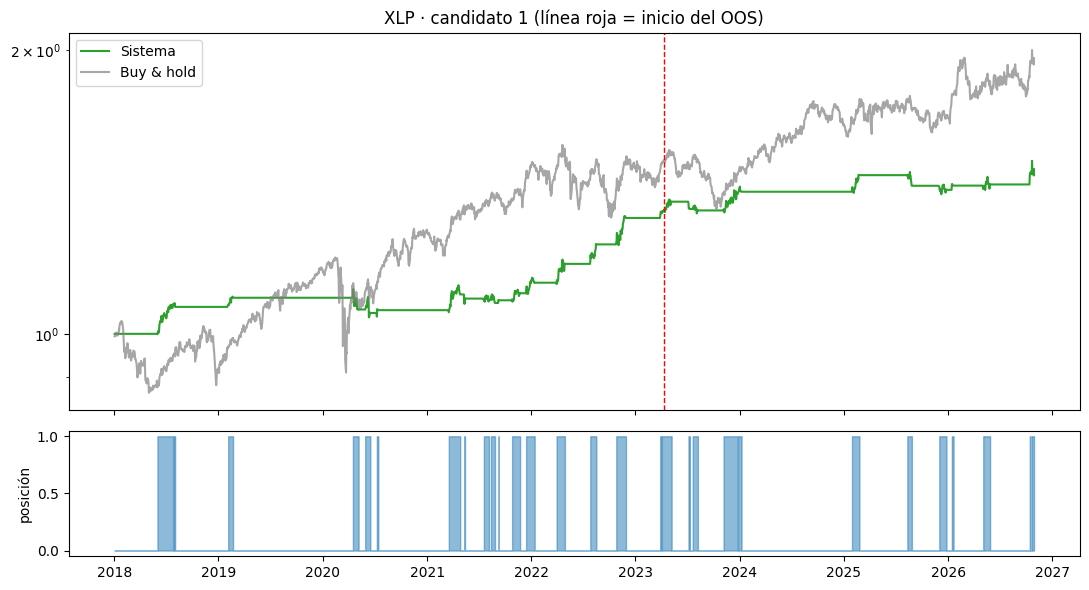

29 operaciones · mejor 7.4% · peor -2.8% · Sharpe total sin la mejor operación: 0.76 (con ella: 0.89)
Exportado en resultados_grid/XLP_20261030_1155/: XLP_c1_daily.csv y XLP_c1_contexto.txt
Origen: casi-aprobados (NO supera todos los filtros)
EMA3X(f=30,m=120,s=65) OR MACD(f=8,s=21,sig=16,modo=senal)
Sharpe IS 0.94 · OOS 0.66 · total 0.84 | WR IS 57% · PF IS 3.9 | CAGR 10.4% · MaxDD -16.9%


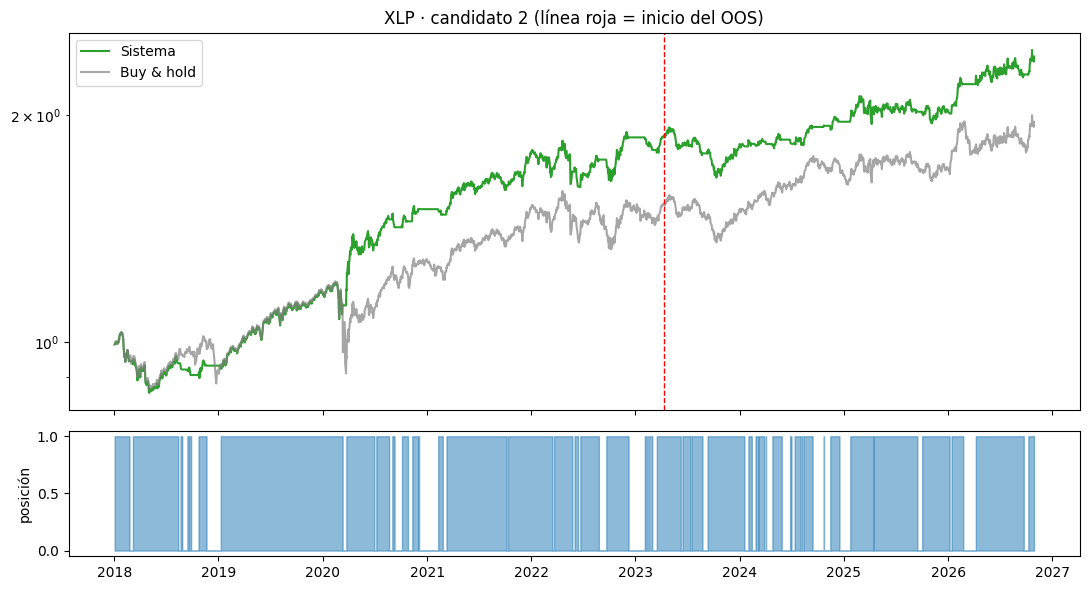

43 operaciones · mejor 20.4% · peor -5.5% · Sharpe total sin la mejor operación: 0.72 (con ella: 0.84)
Exportado en resultados_grid/XLP_20261030_1155/: XLP_c2_daily.csv y XLP_c2_contexto.txt


In [9]:
# =====================================================================================
# 9) Inspeccionar un candidato y exportarlo al formato del portfolio
# =====================================================================================
CANDIDATO = [1, 2]        # nº(s) del candidato a revisar y exportar (de la shortlist o de los casi-aprobados, según FUENTE_CANDIDATO). Un número o una lista
EXPORTAR  = True         # True -> escribe {TICKER}_c<nº>_daily.csv y {TICKER}_c<nº>_contexto.txt de cada candidato elegido en la carpeta de la ejecución

FUENTE = SHORT if (FUENTE_CANDIDATO == "shortlist" or (FUENTE_CANDIDATO == "auto" and len(SHORT))) else CASI_DF
ORIGEN = "shortlist (supera los filtros)" if FUENTE is SHORT else "casi-aprobados (NO supera todos los filtros)"
for _n in (CANDIDATO if isinstance(CANDIDATO, (list, tuple)) else [CANDIDATO]):
    if len(FUENTE) >= _n:
        c = FUENTE.loc[_n]
        sig = reconstruir_sig(c)
        DIAG = "supera todos los filtros" if FUENTE is SHORT else "NO supera los filtros -> " + str(c["falla"])
        print(f"Origen: {ORIGEN}")
        pos = posiciones(sig[None, :])
        R = retornos_estrategia(pos)[0]
        fechas = dates[w0:]
        eq_s = pd.Series(np.cumprod(1 + R), index=fechas); eq_b = pd.Series(np.cumprod(1 + ret[w0:]), index=fechas)
        print(c["combinacion"])
        print(f"Sharpe IS {c['sharpe_IS']:.2f} · OOS {c['sharpe_OOS']:.2f} · total {c['sharpe_ALL']:.2f} | WR IS {c['wr_IS']:.0%} · PF IS {c['pf_IS']:.1f} | CAGR {c['cagr_ALL']:.1%} · MaxDD {c['maxdd_ALL']:.1%}")
        fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
        ax[0].plot(eq_s, label="Sistema", color="tab:green"); ax[0].plot(eq_b, label="Buy & hold", color="gray", alpha=.7)
        ax[0].axvline(dates[ie], color="red", ls="--", lw=1); ax[0].set_yscale("log"); ax[0].legend(); ax[0].set_title(f"{TICKER} · candidato {_n} (línea roja = inicio del OOS)")
        ax[1].fill_between(fechas, 0, pos[0, w0:], step="post", color="tab:blue", alpha=.5); ax[1].set_ylabel("posición")
        plt.tight_layout(); plt.savefig(f"{RUN}/grafico_candidato{_n}.png", dpi=110); plt.show()
        pw = pos[0, w0:]
        tr = trades_retornos(pw, R)
        # Sharpe de toda la ventana quitando la mejor operación (sus días pasan a retorno 0): mide la dependencia de una sola operación
        prev_ = np.concatenate([[0], pw[:-1]]); tid_ = np.where((pw > 0) | (prev_ > 0), np.cumsum((pw > 0) & (prev_ == 0)), 0)
        R2 = R.copy(); R2[tid_ == (np.argmax(tr) + 1)] = 0.0
        sh2 = (R2.mean() - rf_d) / R2.std(ddof=1) * math.sqrt(ANUAL)
        print(f"{len(tr)} operaciones · mejor {tr.max():.1%} · peor {tr.min():.1%} · Sharpe total sin la mejor operación: {sh2:.2f} (con ella: {c['sharpe_ALL']:.2f})")

        if EXPORTAR:
            _d = EXEC_DELAY - 1       # el portfolio exige position[t] = signal_next[t-1]: con EXEC_DELAY=2 la columna signal_next ya lleva el día extra
            sig_w = (np.concatenate([np.zeros(_d, dtype=sig.dtype), sig[:len(sig) - _d]]) if _d else sig)[w0:]
            es_frac = sig.dtype.kind == "f"; _v = "size" if es_frac else "position"
            out = pd.DataFrame({"date": fechas, "bh_return": ret[w0:], "strategy_return": R, "position": (pw > 0).astype(int),
                                "size": pw.astype(float), "signal_next": (sig_w if es_frac else sig_w.astype(int))})
            out["estado"] = "cerrada"
            out.loc[out.index[-1], "estado"] = "provisional"
            out.to_csv(f"{RUN}/{TICKER}_c{_n}_daily.csv", index=False)
            txt = (f"instrumento y calendario: {TICKER} (ETF), calendario de {'7 días (24/7), OJO: el portfolio espera L-V' if ES_7D else '5 días (L-V)'}; ejecución EXEC_DELAY={EXEC_DELAY}; {len(out)} filas, {fechas[0].date()} -> {fechas[-1].date()}\n"
                   f"periodo de diseño y OOS: diseño (IS) {dates[w0].date()} -> {dates[ie-1].date()} · OOS {dates[ie].date()} -> {fechas[-1].date()}; el historial anterior solo calienta medias\n"
                   f"coste asumido: {COST_BPS:g} pb por lado sobre cada cambio de posición (strategy_return viene neto) · rentabilidad del capital fuera de mercado: 0.0% anual\n"
                   f"sistema y tipo de sleeve: {c['combinacion']} · {'tamaño fraccional (columna size), ensemble de votos' if es_frac else '0/1, entrada y salida por señal'}\n---\n"
                   f"estado del sleeve: provisional\n"
                   f"convención: strategy_return[t] = {_v}[t]·bh_return[t] − |Δ{_v}|·coste, con {_v}[t] = signal_next[t−1]\n"
                   f"estado frente a los filtros de Rick: {DIAG}\n"
                   f"validación: Sharpe IS {c['sharpe_IS']:.2f} · OOS {c['sharpe_OOS']:.2f} · total {c['sharpe_ALL']:.2f} · MaxDD {c['maxdd_ALL']:.1%} · WR IS {c['wr_IS']:.0%} · PF IS {c['pf_IS']:.1f} · DSR IS {c['dsr_is']:.2f} · bloques IS {c['sh_bloques']} · PSA {c['psa_pct']:.0%} vecinos sanos\n"
                   f"filtros usados: Sharpe>={SHARPE_MIN:g}, WR>={WINRATE_MIN:.0%}, PF>={PF_MIN:g}, OOS>{OOS_SHARPE_MIN:g}, modo '{FILTRO_MODO}'; {N_PRUEBAS:,} pruebas\n")
            open(f"{RUN}/{TICKER}_c{_n}_contexto.txt", "w", encoding="utf8").write(txt)
            print(f"Exportado en {RUN}/: {TICKER}_c{_n}_daily.csv y {TICKER}_c{_n}_contexto.txt")
    else:
        print("No hay candidato con ese número en la lista elegida (shortlist o casi-aprobados).")

FASE 4: 45 variantes = 5 candidatos base x capas (vol sizing, redondeo, filtro). Sirve para ver si una capa mejora la ROBUSTEZ del sistema, no para repetir la búsqueda.
Sharpe total de las 45 variantes: mediana 0.78 · p10 0.43 · p90 0.89 · máximo 0.94   (buy & hold: 0.57)
Sharpe OOS: mediana 0.07   ·   variantes con Sharpe IS >= 1.35 y OOS > 1: 0   ·   pasan los filtros completos: full 0 / is 0

Las 15 mejores (ordenadas por sharpe_ALL):



,variante,sharpe_IS,sharpe_OOS,sharpe_ALL,cagr_ALL,maxdd_ALL,expo_IS,expo_ALL,tr_ano,giro_ano,wr_ALL,pf_ALL,dsr_is,pasa_full,pasa_is
1,"#4 EMA3X(f=20,m=80,s=65) AND MACD(f=8,s=50,sig...",1.291,-0.020,0.941,0.036,-0.039,0.088,0.061,1.134,2.267,0.700,18.356,0.982,False,False
2,"#4 EMA3X(f=20,m=80,s=65) AND MACD(f=8,s=50,sig...",1.286,-0.020,0.927,0.032,-0.039,0.085,0.059,1.134,2.154,0.700,16.588,0.977,False,False
3,"#1 EMA3X(f=30,m=80,s=65) AND MACD(f=12,s=35,si...",1.136,0.600,0.923,0.047,-0.053,0.181,0.176,3.287,6.405,0.655,4.720,0.931,False,False
4,"#4 EMA3X(f=20,m=80,s=65) AND MACD(f=8,s=50,sig...",1.249,-0.049,0.918,0.030,-0.039,0.084,0.057,1.134,2.097,0.700,15.007,0.971,False,False
5,"#1 EMA3X(f=30,m=80,s=65) AND MACD(f=12,s=35,si...",1.091,0.600,0.899,0.047,-0.059,0.184,0.178,3.287,6.462,0.655,4.496,0.916,False,False
6,"#1 EMA3X(f=30,m=80,s=65) AND MACD(f=12,s=35,si...",1.069,0.600,0.887,0.047,-0.066,0.185,0.178,3.287,6.462,0.655,4.460,0.908,False,False
7,"#3 EMA3X(f=30,m=80,s=65) AND MACD(f=12,s=35,si...",1.293,0.303,0.863,0.048,-0.083,0.188,0.197,4.194,8.219,0.568,3.441,0.967,False,False
8,"#5 EMA3X(f=30,m=100,s=65) AND MACD(f=8,s=26,si...",1.173,0.393,0.861,0.044,-0.071,0.180,0.178,3.401,6.632,0.667,4.747,0.942,False,False
9,"#3 EMA3X(f=30,m=80,s=65) AND MACD(f=12,s=35,si...",1.245,0.303,0.842,0.047,-0.083,0.192,0.199,4.194,8.275,0.568,3.333,0.958,False,False
10,"#2 EMA3X(f=30,m=120,s=65) OR MACD(f=8,s=21,sig...",0.942,0.664,0.839,0.104,-0.169,0.798,0.782,4.875,9.522,0.628,3.996,0.857,False,False



'expo' = tamaño medio (0-1); 'giro_ano' = suma anual de cambios de tamaño (coste); el DSR usa solo el nº de variantes, así que es mucho más benévolo que el de la búsqueda grande: lee primero la mediana.


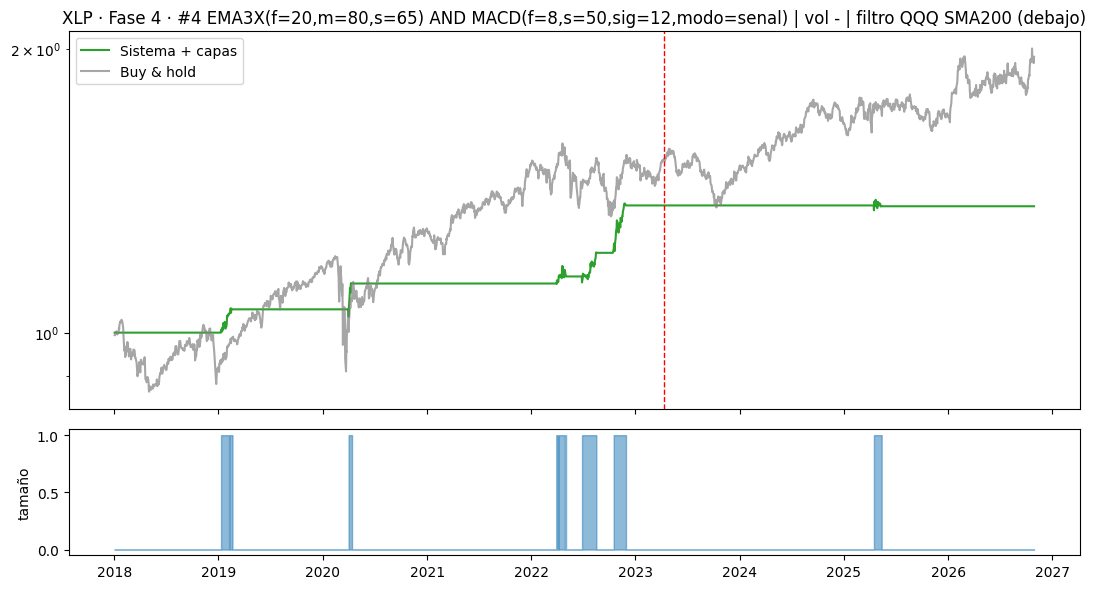

Exportado en resultados_grid/XLP_20261030_1155/: XLP_f4_daily.csv y XLP_f4_contexto.txt (variante 1: #4 EMA3X(f=20,m=80,s=65) AND MACD(f=8,s=50,sig=12,modo=senal) | vol - | filtro QQQ SMA200 (debajo))


In [10]:
# =====================================================================================
# 10) Fase 4 (opcional): capas sobre los mejores candidatos (vol sizing, tamaño fraccional, filtro de otro activo)
# =====================================================================================
if not FASE4:
    print("FASE4 = False: se omite.")
else:
    VOLR = pd.Series(ret).rolling(F4_VOL_N).std().values * math.sqrt(ANUAL)

    def cargar_filtro():
        if not F4_FILTRO_TICKER and not F4_FILTRO_CSV: return None
        if DATA_SOURCE == "yfinance" and not F4_FILTRO_CSV:
            import yfinance as yf
            d = yf.download(F4_FILTRO_TICKER, start=START, auto_adjust=True, progress=False)
            if isinstance(d.columns, pd.MultiIndex): d.columns = d.columns.get_level_values(0)
            d.columns = [x.lower() for x in d.columns]
            c = d["close"]
        else:
            d = pd.read_csv(F4_FILTRO_CSV, parse_dates=["date"], index_col="date"); d.columns = [x.lower() for x in d.columns]
            c = d["close"] if "close" in d.columns else (1 + d["bh_return"].fillna(0)).cumprod()
        c.index = pd.to_datetime(c.index).tz_localize(None)
        return c.sort_index().reindex(dates, method="ffill")

    _cf = cargar_filtro()
    FILT = {}
    if _cf is not None:
        for n_ in F4_FILTRO_SMA:
            FILT[n_] = ((_cf > _cf.rolling(n_).mean()) if F4_FILTRO_MODO == "encima" else (_cf < _cf.rolling(n_).mean())).fillna(False).values.astype(float)

    def evaluar_f(obj):
        pos = np.zeros(T); pos[EXEC_DELAY:] = obj[:-EXEC_DELAY]
        p = pos[w0 - 1:]
        R = p[1:] * ret[w0:] - np.abs(np.diff(p)) * COSTE
        pw = pos[w0:]
        out = {}
        for seg in ("IS", "OOS", "ALL"):
            mw = SEG[seg][w0:]; r = R[mw]; sd = r.std(ddof=1); eq = np.cumprod(1 + r)
            out["sharpe_" + seg] = (r.mean() - rf_d) / sd * math.sqrt(ANUAL) if sd > 0 else 0.0
            out["cagr_" + seg] = eq[-1] ** (1 / YEARS[seg]) - 1
            out["maxdd_" + seg] = (eq / np.maximum.accumulate(eq) - 1).min()
            out["expo_" + seg] = pw[mw].mean()
        prev = np.concatenate([[0.0], pw[:-1]])
        out["tr_ano"] = ((pw > 0) & (prev <= 0)).sum() / YEARS["ALL"]
        out["giro_ano"] = np.abs(np.diff(p)).sum() / YEARS["ALL"]
        pb = (pw > 0).astype(np.int8)
        for seg in ("IS", "ALL"):
            mw = SEG[seg][w0:]
            out["wr_" + seg], out["pf_" + seg] = wr_pf(trades_retornos(pb[mw], R[mw]))
        Ri = R[SEG["IS"][w0:]]
        out["_sk"], out["_ku"] = float(skew(Ri)), float(kurtosis(Ri, fisher=False))
        return out, R, pw

    BASES = []
    _src = SHORT if len(SHORT) else CASI_DF
    for k_ in range(min(F4_TOP, len(_src))):
        c_ = _src.iloc[k_]
        BASES.append((f"#{k_+1} {c_['combinacion'][:70]}", reconstruir_sig(c_).astype(np.float64)))
    filtros = [None] + list(FILT.keys())
    filas4, OBJ4, N_VOTOS = [], {}, {}
    for nb_, base in BASES:
        for vol_obj in F4_VOL_OBJ:
            for fl in filtros:
                tam = base.copy()
                if vol_obj: tam = tam * np.where(np.isnan(VOLR), 1.0, np.minimum(F4_LEV_MAX, vol_obj / np.maximum(VOLR, 1e-6)))
                if fl is not None: tam = tam * FILT[fl]
                if F4_PASO_TAMANO: tam = np.round(tam / F4_PASO_TAMANO) * F4_PASO_TAMANO
                tam = np.clip(tam, 0, F4_LEV_MAX)
                nombre = f"{nb_} | vol {('%g' % vol_obj) if vol_obj else '-'} | filtro {(('%s SMA%d%s' % (F4_FILTRO_TICKER or 'csv', fl, '' if F4_FILTRO_MODO == 'encima' else ' (debajo)')) if fl else '-')}"
                out, R, pw = evaluar_f(tam)
                filas4.append(dict(variante=nombre, **out)); OBJ4[nombre] = tam
    F4D = pd.DataFrame(filas4)
    nv4 = len(F4D)
    var4 = float(np.var(F4D["sharpe_IS"] / math.sqrt(ANUAL)))
    F4D["dsr_is"] = [dsr(r["sharpe_IS"], T_is, r["_sk"], r["_ku"], nv4, var4) for r in F4D.to_dict("records")]
    F4D = F4D.drop(columns=["_sk", "_ku"])
    F4D["pasa_full"] = (F4D.sharpe_ALL >= SHARPE_MIN) & (F4D.wr_ALL >= WINRATE_MIN) & (F4D.pf_ALL >= PF_MIN) & (F4D.sharpe_OOS > OOS_SHARPE_MIN)
    F4D["pasa_is"] = (F4D.sharpe_IS >= SHARPE_MIN) & (F4D.wr_IS >= WINRATE_MIN) & (F4D.pf_IS >= PF_MIN) & (F4D.sharpe_OOS > OOS_SHARPE_MIN)
    F4D = F4D.sort_values(CLAVE_ORDEN, ascending=False).reset_index(drop=True); F4D.index += 1
    sa = F4D["sharpe_ALL"]
    print(f"FASE 4: {nv4} variantes = {len(BASES)} candidatos base x capas (vol sizing, redondeo, filtro). Sirve para ver si una capa mejora la ROBUSTEZ del sistema, no para repetir la búsqueda.")
    print(f"Sharpe total de las {nv4} variantes: mediana {sa.median():.2f} · p10 {sa.quantile(.1):.2f} · p90 {sa.quantile(.9):.2f} · máximo {sa.max():.2f}   (buy & hold: {bh_stats['ALL'][0]:.2f})")
    print(f"Sharpe OOS: mediana {F4D['sharpe_OOS'].median():.2f}   ·   variantes con Sharpe IS >= {SHARPE_MIN:g} y OOS > {OOS_SHARPE_MIN:g}: {int(((F4D.sharpe_IS >= SHARPE_MIN) & (F4D.sharpe_OOS > OOS_SHARPE_MIN)).sum())}   ·   pasan los filtros completos: full {int(F4D.pasa_full.sum())} / is {int(F4D.pasa_is.sum())}\n")
    COLS4 = ["variante", "sharpe_IS", "sharpe_OOS", "sharpe_ALL", "cagr_ALL", "maxdd_ALL", "expo_IS", "expo_ALL", "tr_ano", "giro_ano", "wr_ALL", "pf_ALL", "dsr_is", "pasa_full", "pasa_is"]
    print(f"Las {min(F4_MOSTRAR, nv4)} mejores (ordenadas por {CLAVE_ORDEN}):\n")
    mostrar(F4D[COLS4].head(F4_MOSTRAR).round(3))
    F4D.to_csv(f"{RUN}/fase4_variantes_{TICKER}.csv")
    print("\n'expo' = tamaño medio (0-1); 'giro_ano' = suma anual de cambios de tamaño (coste); el DSR usa solo el nº de variantes, así que es mucho más benévolo que el de la búsqueda grande: lee primero la mediana.")

    if F4_EXPORTAR and len(F4D) >= F4_CANDIDATO:
        c4 = F4D.loc[F4_CANDIDATO]; nom = c4["variante"]; tam = OBJ4[nom]
        out, R, pw = evaluar_f(tam); fechas = dates[w0:]
        eq_s = pd.Series(np.cumprod(1 + R), index=fechas); eq_b = pd.Series(np.cumprod(1 + ret[w0:]), index=fechas)
        fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
        ax[0].plot(eq_s, color="tab:green", label="Sistema + capas"); ax[0].plot(eq_b, color="gray", alpha=.7, label="Buy & hold")
        ax[0].axvline(dates[ie], color="red", ls="--", lw=1); ax[0].set_yscale("log"); ax[0].legend(); ax[0].set_title(f"{TICKER} · Fase 4 · {nom}")
        ax[1].fill_between(fechas, 0, pw, step="post", color="tab:blue", alpha=.5); ax[1].set_ylabel("tamaño")
        plt.tight_layout(); plt.savefig(f"{RUN}/grafico_fase4_{F4_CANDIDATO}.png", dpi=110); plt.show()
        o = pd.DataFrame({"date": fechas, "bh_return": ret[w0:], "strategy_return": R, "position": (pw > 0).astype(int), "size": pw})
        o["estado"] = "cerrada"; o.loc[o.index[-1], "estado"] = "provisional"
        o.to_csv(f"{RUN}/{TICKER}_f4_daily.csv", index=False)
        open(f"{RUN}/{TICKER}_f4_contexto.txt", "w", encoding="utf8").write(
            f"instrumento y calendario: {TICKER}, calendario de {'7 días (24/7), OJO: el portfolio espera L-V' if ES_7D else '5 días (L-V)'}; ejecución EXEC_DELAY={EXEC_DELAY}; {len(o)} filas, {fechas[0].date()} -> {fechas[-1].date()}\n"
            f"periodo de diseño y OOS: IS {dates[w0].date()} -> {dates[ie-1].date()} · OOS {dates[ie].date()} -> {fechas[-1].date()}\n"
            f"coste asumido: {COST_BPS:g} pb por lado sobre cada cambio de tamaño (strategy_return viene neto)\n"
            f"sistema y tipo de sleeve: '{nom}' · tamaño fraccional (columna size, redondeo {F4_PASO_TAMANO}); position = 1 cuando size > 0\n---\n"
            f"convención: strategy_return[t] = size[t]·bh_return[t] − |Δsize|·coste, con size[t] = objetivo calculado al cierre de t−{EXEC_DELAY}\n"
            f"validación: Sharpe IS {c4['sharpe_IS']:.2f} · OOS {c4['sharpe_OOS']:.2f} · total {c4['sharpe_ALL']:.2f} · CAGR {c4['cagr_ALL']:.1%} · MaxDD {c4['maxdd_ALL']:.1%} · exposición media {c4['expo_ALL']:.0%} · "
            f"mediana de las {nv4} variantes {sa.median():.2f} (Sharpe total) · DSR {c4['dsr_is']:.2f}\n")
        print(f"Exportado en {RUN}/: {TICKER}_f4_daily.csv y {TICKER}_f4_contexto.txt (variante {F4_CANDIDATO}: {nom})")

In [11]:
# =====================================================================================
# 11) Validación congelada: los candidatos elegidos, sin tocar nada, sobre datos que no intervinieron
#     - Mismo activo, tramo anterior a EVAL_START (la búsqueda nunca lo vio)
#     - Otros activos con los mismos parámetros (como la validación cruzada con SPY de la plantilla)
# =====================================================================================
if not VAL_ACTIVAR:
    print("VAL_ACTIVAR = False: se omite.")
else:
    _cands = VAL_CANDIDATOS if VAL_CANDIDATOS is not None else CANDIDATO
    _cands = list(_cands) if isinstance(_cands, (list, tuple)) else [_cands]
    _fuente = SHORT if (FUENTE_CANDIDATO == "shortlist" or (FUENTE_CANDIDATO == "auto" and len(SHORT))) else CASI_DF

    def serie_estrategia(sig, ret_a):
        pos = np.zeros(len(sig)); pos[EXEC_DELAY:] = sig[:-EXEC_DELAY]
        R = np.zeros(len(sig)); R[1:] = pos[1:] * ret_a[1:] - np.abs(np.diff(pos)) * COSTE
        return R, pos

    def metricas_tramo(R, pos, ret_a, fechas, m):
        r, p, b = R[m], pos[m], ret_a[m]
        yrs = max((fechas[m][-1] - fechas[m][0]).days / 365.25, 1e-9)
        def blk(x):
            sd = x.std(ddof=1); eq = np.cumprod(1 + x)
            return ((x.mean() - rf_d) / sd * math.sqrt(ANUAL) if sd > 0 else 0.0, eq[-1] ** (1 / yrs) - 1, (eq / np.maximum.accumulate(eq) - 1).min())
        sh, cg, dd = blk(r); bsh, bcg, bdd = blk(b)
        pb = (p > 0).astype(np.int8)
        prev = np.concatenate([[0], pb[:-1]])
        ntr = int(((pb == 1) & (prev == 0)).sum())
        wr, pf = wr_pf(trades_retornos(pb, r))
        # relación con el buy & hold: regresión r = alfa + beta·b (alfa anualizado, t del alfa), Calmar, captura de CAGR y drawdown evitado
        vb = b.var(ddof=1); beta = float(np.cov(r, b, ddof=1)[0, 1] / vb) if vb > 0 else 0.0
        res = (r - rf_d) - beta * (b - rf_d); alfa_d = float(res.mean()); sd_res = float(res.std(ddof=1))
        alfa_t = alfa_d / (sd_res / math.sqrt(len(res))) if sd_res > 0 else 0.0
        calmar = cg / abs(dd) if dd < 0 else 0.0; bcalmar = bcg / abs(bdd) if bdd < 0 else 0.0
        captura = cg / bcg if bcg > 0 else float("nan"); dd_ev = 1 - abs(dd) / abs(bdd) if bdd < 0 else float("nan")
        return dict(anos=yrs, sharpe=sh, cagr=cg, maxdd=dd, expo=float(p.mean()), ops=ntr, ops_ano=ntr / yrs, wr=wr, pf=pf,
                    bh_sharpe=bsh, bh_cagr=bcg, bh_maxdd=bdd, beta=beta, alfa=alfa_d * ANUAL, alfa_t=alfa_t,
                    calmar=calmar, bh_calmar=bcalmar, captura=captura, dd_evitado=dd_ev)

    def senal_en(df2, c):
        """Recalcula las señales de un candidato (mismos parámetros) sobre otro activo. Cambia temporalmente close/high/low."""
        global close, high, low
        guardado = (close, high, low); cache = dict(_ema_cache); _ema_cache.clear()
        try:
            close, high, low = df2["close"], df2["high"], df2["low"]
            mats = []
            for n, i in zip(c["nombres"], c["idx"]):
                p_ = IND[n]["params"][i]
                g = {("modos" if k == "modo" else k): [v] for k, v in p_.items()}
                mats.append(REGISTRO[n](g)[1][0])
        finally:
            close, high, low = guardado; _ema_cache.clear(); _ema_cache.update(cache)
        sg = mats[0].copy()
        for m_ in mats[1:]:
            sg = (sg | m_) if c["logica"] == "OR" else (sg & m_)
        return sg

    def cargar_otro(ref):
        if DATA_SOURCE == "yfinance":
            import yfinance as yf
            d = yf.download(ref, start=START, auto_adjust=True, progress=False)
            if isinstance(d.columns, pd.MultiIndex): d.columns = d.columns.get_level_values(0)
            d.columns = [x.lower() for x in d.columns]; d = d[["open", "high", "low", "close"]].dropna()
        else:
            d = pd.read_csv(ref, parse_dates=["date"], index_col="date"); d.columns = [x.lower() for x in d.columns]
            if "close" not in d.columns:
                cc = (1 + d["bh_return"].fillna(0)).cumprod() * 100; d = pd.DataFrame({"open": cc, "high": cc, "low": cc, "close": cc})
        d.index = pd.to_datetime(d.index).tz_localize(None); d = d.sort_index()
        if not ES_7D: d = d[d.index.dayofweek < 5]
        return d

    # ---- sistemas escritos a mano (VAL_MANUAL): se convierten en señales con los mismos indicadores del grid ----
    def parsear_manual(txt):
        import re
        partes = re.split(r"\s+(OR|AND)\s+", txt.strip())
        terminos = partes[0::2]; logs = set(partes[1::2])
        if len(logs) > 1: raise ValueError("mezcla OR y AND: usa una sola lógica por sistema")
        logica = logs.pop() if logs else "SOLO"
        specs = []
        for t_ in terminos:
            mm = re.match(r"^(\w+)\((.*)\)$", t_.strip())
            if not mm or mm.group(1) not in REGISTRO: raise ValueError(f"término no reconocido: {t_!r} (indicadores: {', '.join(REGISTRO)})")
            g = {}
            for kv in [x for x in mm.group(2).split(",") if x.strip()]:
                k, v = [y.strip() for y in kv.split("=")]
                try: v = int(v)
                except ValueError:
                    try: v = float(v)
                    except ValueError: pass
                g["modos" if k == "modo" else k] = [v]
            if mm.group(1) == "MACD":
                g.setdefault("sig", [0]); g["modos"] = [g.get("modos", ["cero" if g["sig"][0] == 0 else "senal"])[0]]
            specs.append((mm.group(1), g))
        return logica, specs

    def sig_manual(logica, specs):
        mats = []
        for n, g in specs:
            P_, S_ = REGISTRO[n](g)
            if len(P_) == 0: raise ValueError(f"{n}{g}: parámetros no válidos (p. ej. en EMA3 debe cumplirse f < m < s)")
            mats.append(S_[0])
        sg = mats[0].copy()
        for m_ in mats[1:]:
            sg = (sg | m_) if logica == "OR" else (sg & m_)
        return sg

    def senal_manual_en(df2, logica, specs):
        global close, high, low
        guardado = (close, high, low); cache = dict(_ema_cache); _ema_cache.clear()
        try:
            close, high, low = df2["close"], df2["high"], df2["low"]
            return sig_manual(logica, specs)
        finally:
            close, high, low = guardado; _ema_cache.clear(); _ema_cache.update(cache)

    # lista unificada de lo que se valida: (etiqueta, señal, es_ensemble, sharpe de la búsqueda o None, función para otro activo)
    items_v = []
    for n_ in _cands:
        if len(_fuente) < n_: continue
        c = _fuente.loc[n_]
        items_v.append((f"#{n_} {c['combinacion'][:60]}", reconstruir_sig(c), c["logica"] == "ENS", c["sharpe_ALL"], (lambda d2, c=c: senal_en(d2, c))))
    for txt_ in (VAL_MANUAL or []):
        try:
            lg_, sp_ = parsear_manual(txt_)
            items_v.append((f"MANUAL {txt_[:60]}", sig_manual(lg_, sp_), False, None, (lambda d2, lg_=lg_, sp_=sp_: senal_manual_en(d2, lg_, sp_))))
        except Exception as e_:
            print(f"  VAL_MANUAL: no se pudo interpretar {txt_!r}: {e_}")

    filas_v = []
    for etiqueta_c, sig, es_ens, sh_ref, f_otro in items_v:
        R0, pos0 = serie_estrategia(sig, ret)
        m0 = np.arange(T) >= w0
        met0 = metricas_tramo(R0, pos0, ret, dates, m0)
        if sh_ref is not None:
            print(f"[control] {etiqueta_c}: Sharpe total recalculado {met0['sharpe']:.3f} vs búsqueda {sh_ref:.3f}")
        else:
            print(f"[manual] {etiqueta_c}: ventana de evaluación {dates[w0].date()}→{dates[-1].date()} con EXEC_DELAY={EXEC_DELAY} y {COST_BPS:g} pb -> "
                  f"Sharpe {met0['sharpe']:.3f} · CAGR {met0['cagr']:.1%} · MaxDD {met0['maxdd']:.1%} · {met0['ops']} operaciones (buy & hold: Sharpe {met0['bh_sharpe']:.3f})")
        # (a) mismo activo, tramos que la búsqueda no vio
        if VAL_PERIODOS:
            tramos = VAL_PERIODOS
            if tramos == "auto":
                ini = dates[min(VAL_WARMUP, w0 - 1)]; tramos = [(str(ini.date()), str(dates[w0 - 1].date()))] if w0 > VAL_WARMUP + 60 else []
                if not tramos: print("  (no hay historial suficiente anterior a EVAL_START: baja START o VAL_WARMUP)")
            for a_, b_ in tramos:
                m = (dates >= pd.Timestamp(a_)) & (dates <= pd.Timestamp(b_)) & (np.arange(T) >= VAL_WARMUP)
                if m.sum() > 60:
                    filas_v.append(dict(candidato=etiqueta_c, donde=f"{TICKER} {dates[m][0].date()}→{dates[m][-1].date()}", **metricas_tramo(R0, pos0, ret, dates, m)))
        # (b) otros activos, parámetros congelados
        if es_ens and VAL_ACTIVOS:
            print(f"  {etiqueta_c}: los ensembles no se recalculan sobre otros activos (solo el tramo previo del mismo activo).")
        elif VAL_ACTIVOS:
            for ref in VAL_ACTIVOS:
                try:
                    d2 = cargar_otro(ref)
                    sg2 = f_otro(d2); ret2 = d2["close"].pct_change().fillna(0.0).values
                    R2_, pos2 = serie_estrategia(sg2, ret2); m2 = np.arange(len(d2)) >= VAL_WARMUP
                    if VAL_ACTIVOS_TRAMO: m2 = m2 & (d2.index >= pd.Timestamp(VAL_ACTIVOS_TRAMO[0])) & (d2.index <= pd.Timestamp(VAL_ACTIVOS_TRAMO[1]))
                    if m2.sum() > 60:
                        filas_v.append(dict(candidato=etiqueta_c, donde=f"{os.path.basename(str(ref))} {d2.index[m2][0].date()}→{d2.index[m2][-1].date()}",
                                            **metricas_tramo(R2_, pos2, ret2, d2.index, m2)))
                except Exception as e_:
                    print(f"  No se pudo validar en {ref}: {e_}")
    if filas_v:
        VAL = pd.DataFrame(filas_v)
        VAL["veredicto"] = np.where((VAL["ops"] < 5) | (VAL["anos"] < 1), "pocos datos", np.where((VAL["sharpe"] >= VAL_SHARPE_OK) & (VAL["sharpe"] > 0), "mantiene", "NO mantiene"))
        VAL["vs_bh"] = np.where((VAL["ops"] < 5) | (VAL["anos"] < 1), "pocos datos",
                       np.where(VAL["calmar"] > VAL["bh_calmar"], "mejora riesgo/retorno",
                       np.where((VAL["captura"] >= VAL_CAPTURA_MIN) & (VAL["dd_evitado"] >= VAL_DD_EVITADO_MIN), "reduce riesgo", "no aporta")))
        cols = ["candidato", "donde", "anos", "sharpe", "bh_sharpe", "cagr", "bh_cagr", "maxdd", "bh_maxdd", "expo", "ops", "ops_ano", "wr", "pf", "veredicto"]
        cols_bh = ["candidato", "beta", "alfa", "alfa_t", "calmar", "bh_calmar", "captura", "dd_evitado", "vs_bh"]
        print("\nVALIDACIÓN CONGELADA (mismos parámetros, mismos costes y ejecución; 'bh_' = buy & hold del mismo tramo):\n")
        mostrar(VAL[cols].round(3))
        print("\nFRENTE AL BUY & HOLD (para activos donde el buy & hold ya es muy bueno, superarlo en Sharpe no es la vara adecuada):")
        print("  alfa = rentabilidad anual no explicada por la exposición al activo (beta) · alfa_t = su t-stat · calmar = CAGR/|MaxDD| · captura = CAGR del sistema / CAGR del buy & hold")
        print(f"  dd_evitado = 1 - |MaxDD sistema| / |MaxDD buy & hold| · vs_bh: 'mejora riesgo/retorno' si calmar > el del buy & hold; 'reduce riesgo' si captura >= {VAL_CAPTURA_MIN:g} y dd_evitado >= {VAL_DD_EVITADO_MIN:g}; si no, 'no aporta'\n")
        mostrar(VAL[cols_bh].round(3))
        VAL[cols + cols_bh[1:]].to_csv(f"{RUN}/validacion_congelada_{TICKER}.csv", index=False)
        print("\nCómo leerlo: estos datos no entraron en ninguna elección, así que aquí no hay sesgo de selección. Con pocas operaciones el resultado es ruidoso;"
              " lo que importa es que el Sharpe se mantenga claramente positivo y que el drawdown sea menor que el del buy & hold, no que iguale el del backtest.")
    else:
        print("No hay nada que validar con esta configuración (revisa VAL_PERIODOS / VAL_ACTIVOS / CANDIDATO).")

[control] #1 EMA3X(f=30,m=80,s=65) AND MACD(f=12,s=35,sig=9,modo=senal) A: Sharpe total recalculado 0.887 vs búsqueda 0.887
[control] #2 EMA3X(f=30,m=120,s=65) OR MACD(f=8,s=21,sig=16,modo=senal): Sharpe total recalculado 0.839 vs búsqueda 0.839

VALIDACIÓN CONGELADA (mismos parámetros, mismos costes y ejecución; 'bh_' = buy & hold del mismo tramo):



,candidato,donde,anos,sharpe,bh_sharpe,cagr,bh_cagr,maxdd,bh_maxdd,expo,ops,ops_ano,wr,pf,veredicto
0,"#1 EMA3X(f=30,m=80,s=65) AND MACD(f=12,s=35,si...",XLP 2000-04-10→2017-12-29,17.719,-0.003,0.615,-0.002,0.08,-0.325,-0.359,0.212,90,5.079,0.433,0.992,NO mantiene
1,"#2 EMA3X(f=30,m=120,s=65) OR MACD(f=8,s=21,sig...",XLP 2000-04-10→2017-12-29,17.719,0.396,0.615,0.043,0.08,-0.403,-0.359,0.827,76,4.289,0.408,2.068,NO mantiene



FRENTE AL BUY & HOLD (para activos donde el buy & hold ya es muy bueno, superarlo en Sharpe no es la vara adecuada):
  alfa = rentabilidad anual no explicada por la exposición al activo (beta) · alfa_t = su t-stat · calmar = CAGR/|MaxDD| · captura = CAGR del sistema / CAGR del buy & hold
  dd_evitado = 1 - |MaxDD sistema| / |MaxDD buy & hold| · vs_bh: 'mejora riesgo/retorno' si calmar > el del buy & hold; 'reduce riesgo' si captura >= 0.5 y dd_evitado >= 0.3; si no, 'no aporta'



,candidato,beta,alfa,alfa_t,calmar,bh_calmar,captura,dd_evitado,vs_bh
0,"#1 EMA3X(f=30,m=80,s=65) AND MACD(f=12,s=35,si...",0.168,-0.015,-1.175,-0.006,0.223,-0.023,0.094,no aporta
1,"#2 EMA3X(f=30,m=120,s=65) OR MACD(f=8,s=21,sig...",0.807,-0.020,-1.487,0.107,0.223,0.540,-0.124,no aporta



Cómo leerlo: estos datos no entraron en ninguna elección, así que aquí no hay sesgo de selección. Con pocas operaciones el resultado es ruidoso; lo que importa es que el Sharpe se mantenga claramente positivo y que el drawdown sea menor que el del buy & hold, no que iguale el del backtest.


In [12]:
# =====================================================================================
# 12) Informe de la ejecución (todo lo impreso + configuración) -> .txt para compartirlo
# =====================================================================================
_nombres_cfg = ["TICKER", "DATA_SOURCE", "START", "EVAL_START", "IS_END", "IS_FRAC", "COST_BPS", "EXEC_DELAY", "CALENDARIO", "RF_ANUAL",
                "SHARPE_MIN", "WINRATE_MIN", "PF_MIN", "OOS_SHARPE_MIN", "MIN_TRADES_ANO", "MAX_TRADES_ANO", "MIN_EXPOSICION",
                "FILTRO_MODO", "INDICADORES", "TAMANOS", "LOGICAS", "TOP_K_PARES", "TOP_K_TRIOS", "MAX_COMBOS_FAMILIA",
                "SEMILLA", "ORDENAR_POR", "N_SHORTLIST", "NEAR_N", "FUENTE_CANDIDATO", "ENSEMBLES", "ENS_TOPKS", "ENS_UMBRALES", "ENS_FORMAS", "ENS_PASOS", "ENS_MAX_FAMILIAS", "PSA_METRICA", "POOL_PSA", "QUITAR_DUPLICADOS", "DEDUPE_CORR", "BLOQUES_IS", "BLOQUE_SHARPE_MIN", "PSA_RATIO", "PSA_MIN_PCT", "CANDIDATO", "EXPORTAR", "FASE4", "F4_TOP", "F4_VOL_OBJ", "F4_VOL_N", "F4_PASO_TAMANO", "F4_LEV_MAX", "F4_FILTRO_TICKER", "F4_FILTRO_SMA", "F4_FILTRO_MODO", "VAL_ACTIVAR", "VAL_CANDIDATOS", "VAL_MANUAL", "VAL_PERIODOS", "VAL_ACTIVOS", "VAL_ACTIVOS_TRAMO", "VAL_WARMUP", "VAL_CAPTURA_MIN", "VAL_DD_EVITADO_MIN", "VAL_SHARPE_OK"]
_cfg = ", ".join(f"{k}={globals()[k]!r}" for k in _nombres_cfg if k in globals())
_cab = ("=" * 100 + f"\nINFORME · Grid research en batería · {TICKER}\nGenerado: {datetime.datetime.now():%Y-%m-%d %H:%M}\n"
        f"Ventana de trabajo {dates[w0].date()} -> {dates[-1].date()} · IS hasta {dates[ie-1].date()} · OOS desde {dates[ie].date()}\n"
        f"Calendario: {'7 días (24/7)' if ES_7D else 'L-V'} · anualización {ANUAL}\nConfiguración: {_cfg}\nGRIDS: {GRIDS}\n" + "=" * 100 + "\n\n")
_texto = _cab + "".join(LOG.buf)
ruta_informe = f"{RUN}/informe_{TICKER}.txt"
open(ruta_informe, "w", encoding="utf8").write(_texto)
print(f"Informe guardado: {ruta_informe}")
print("Archivos de esta ejecución:", sorted(os.listdir(RUN)))

Informe guardado: resultados_grid/XLP_20261030_1155/informe_XLP.txt
Archivos de esta ejecución: ['XLP_c1_contexto.txt', 'XLP_c1_daily.csv', 'XLP_c2_contexto.txt', 'XLP_c2_daily.csv', 'XLP_f4_contexto.txt', 'XLP_f4_daily.csv', 'casi_aprobados_XLP.csv', 'fase4_variantes_XLP.csv', 'grafico_candidato1.png', 'grafico_candidato2.png', 'grafico_fase4_1.png', 'informe_XLP.txt', 'validacion_congelada_XLP.csv']


### Notas de uso

- **Orden de trabajo recomendado:** 1) deja los filtros de Rick, 2) ejecuta con `FILTRO_MODO="alguno"` para ver las dos lecturas, 3) revisa el embudo (cuántas combinaciones sobreviven a cada filtro), 4) mira el DSR y la concentración en pocas operaciones antes de elegir.
- **Si no pasa nada:** es información. Con un Sharpe mínimo de 1,45 y un profit factor de 2,5 es normal que casi nada sobreviva en un activo de Sharpe bajo; no relajes los filtros hasta ver los casi-aprobados de la celda 8.
- **Si pasan demasiadas:** sube `SHARPE_MIN`, baja `TOP_K_*` o `TAMANOS`. Más pruebas aumentan el riesgo de elegir ruido.
- **Cuidado con el OOS:** cada vez que miras el OOS para decidir, lo desgastas un poco. Fija los filtros antes de ejecutar y no los ajustes mirando qué candidato sale.
- **Win rate y profit factor** se calculan por operación (retorno compuesto de cada tramo con posición, incluidos los costes de entrada y salida). Una operación abierta al final del tramo cuenta con lo que lleva.
- **Los indicadores de estado con memoria** (Donchian y Keltner) entran y salen con reglas distintas; el resto son estados instantáneos (`precio > media`, etc.).